In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from IPython.display import display

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

sales_matches = list(drive_root.rglob("bbq_sauce_sales.csv"))
climate_matches = list(drive_root.rglob("climate_data_2026.csv"))

print("Sales files found:", sales_matches)
print("Climate files found:", climate_matches)

if len(sales_matches) != 1 or len(climate_matches) != 1:
    raise ValueError(
        "Expected exactly one match for each CSV. "
        "Check the printed paths and select the correct files."
    )

sales_path = sales_matches[0]
climate_path = climate_matches[0]

sales_df = pd.read_csv(sales_path)
climate_df = pd.read_csv(climate_path)

print("Sales dataset shape:", sales_df.shape)
print("Climate dataset shape:", climate_df.shape)

print("\nSales data:")
display(sales_df.head())

print("\nClimate data:")
display(climate_df.head())


Sales files found: [PosixPath('/content/drive/MyDrive/DSSB Digital Transformations/bbq_sauce_sales.csv')]
Climate files found: [PosixPath('/content/drive/MyDrive/DSSB Digital Transformations/climate_data_2026.csv')]
Sales dataset shape: (1385, 2)
Climate dataset shape: (1386, 10)

Sales data:


,date,amount
0,2021-01-03,285
1,2021-01-06,627
2,2021-01-07,241
3,2021-01-08,356
4,2021-01-09,877



Climate data:


,date,mean_temp_nationwide,min_temp_nationwide,max_temp_nationwide,mean_precipitation_mm_nationwide,min_precipitation_mm_nationwide,max_precipitation_mm_nationwide,mean_sun_hours_nationwide,min_sun_hours_nationwide,max_sun_hours_nationwide
0,2021-01-03,5.24,3.3,7.8,2.61,0.7,6.6,0.577778,0.0,4.2
1,2021-01-06,3.07,-0.6,5.6,0.30,0.0,1.7,3.866667,0.0,8.2
2,2021-01-07,3.90,1.0,6.9,0.48,0.0,1.6,0.411111,0.0,1.4
3,2021-01-08,6.12,2.4,9.3,3.60,0.0,13.6,0.022222,0.0,0.2
4,2021-01-09,9.16,7.0,11.4,4.84,0.0,10.9,1.377778,0.0,7.6


In [ ]:

for name, df in [
    ("Sales", sales_df),
    ("Climate", climate_df)
]:
    print(f"\n{'='*50}")
    print(f"{name.upper()} DATASET")
    print(f"{'='*50}")

    print("\nShape:", df.shape)
    print("\nColumns:", df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nSummary statistics:")
    display(df.describe(include="all"))



SALES DATASET

Shape: (1385, 2)

Columns: ['date', 'amount']

Data types:
date      object
amount     int64
dtype: object

Missing values:
date      0
amount    0
dtype: int64

Duplicate rows: 0

Summary statistics:


,date,amount
count,1385,1385.000000
unique,1385,NaN
top,2026-07-29,NaN
freq,1,NaN
mean,NaN,483.719856
std,NaN,860.136796
min,NaN,0.000000
25%,NaN,35.000000
50%,NaN,105.000000
75%,NaN,523.000000



CLIMATE DATASET

Shape: (1386, 10)

Columns: ['date', 'mean_temp_nationwide', 'min_temp_nationwide', 'max_temp_nationwide', 'mean_precipitation_mm_nationwide', 'min_precipitation_mm_nationwide', 'max_precipitation_mm_nationwide', 'mean_sun_hours_nationwide', 'min_sun_hours_nationwide', 'max_sun_hours_nationwide']

Data types:
date                                 object
mean_temp_nationwide                float64
min_temp_nationwide                 float64
max_temp_nationwide                 float64
mean_precipitation_mm_nationwide    float64
min_precipitation_mm_nationwide     float64
max_precipitation_mm_nationwide     float64
mean_sun_hours_nationwide           float64
min_sun_hours_nationwide            float64
max_sun_hours_nationwide            float64
dtype: object

Missing values:
date                                0
mean_temp_nationwide                0
min_temp_nationwide                 0
max_temp_nationwide                 0
mean_precipitation_mm_nationwide    0
min_precip

,date,mean_temp_nationwide,min_temp_nationwide,max_temp_nationwide,mean_precipitation_mm_nationwide,min_precipitation_mm_nationwide,max_precipitation_mm_nationwide,mean_sun_hours_nationwide,min_sun_hours_nationwide,max_sun_hours_nationwide
count,1386,1386.000000,1386.000000,1386.000000,1386.000000,1386.000000,1386.000000,1386.000000,1386.000000,1386.000000
unique,1385,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2025-02-28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,11.354715,9.136364,13.500577,2.015693,0.099711,7.315729,5.173401,2.282673,8.427996
std,NaN,6.865106,6.924985,6.980012,2.694028,0.441478,9.554908,3.926723,3.496246,4.223050
min,NaN,-6.940000,-12.300000,-4.700000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,5.932500,3.600000,7.900000,0.030000,0.000000,0.300000,1.844444,0.000000,5.000000
50%,NaN,10.920000,9.100000,12.800000,0.975000,0.000000,4.200000,4.375000,0.300000,8.700000
75%,NaN,17.405000,15.100000,19.600000,2.997500,0.000000,10.800000,7.852778,3.200000,11.900000


In [ ]:

# Preserve original dataframes
sales = sales_df.copy()
climate = climate_df.copy()

# Standardize column names
sales.columns = sales.columns.str.strip().str.lower()
climate.columns = climate.columns.str.strip().str.lower()

# Convert dates
sales["date"] = pd.to_datetime(
    sales["date"], errors="coerce"
)
climate["date"] = pd.to_datetime(
    climate["date"], errors="coerce"
)

for name, df in [("Sales", sales), ("Climate", climate)]:
    print(f"\n{name} date range:")
    print("Start:", df["date"].min())
    print("End:", df["date"].max())

    print("Invalid dates:", df["date"].isna().sum())
    print("Duplicate dates:", df["date"].duplicated().sum())

    display(
        df[df["date"].duplicated(keep=False)]
        .sort_values("date")
        .head(20)
    )



Sales date range:
Start: 2021-01-03 00:00:00
End: 2026-07-29 00:00:00
Invalid dates: 0
Duplicate dates: 0


,date,amount



Climate date range:
Start: 2021-01-03 00:00:00
End: 2026-07-29 00:00:00
Invalid dates: 0
Duplicate dates: 1


,date,mean_temp_nationwide,min_temp_nationwide,max_temp_nationwide,mean_precipitation_mm_nationwide,min_precipitation_mm_nationwide,max_precipitation_mm_nationwide,mean_sun_hours_nationwide,min_sun_hours_nationwide,max_sun_hours_nationwide
1035,2025-02-28,4.35,2.5,5.6,0.0,0.0,0.0,1.700000,0.0,4.0
1036,2025-02-28,5.82,3.6,7.9,0.0,0.0,0.0,3.814286,1.4,9.2


In [ ]:

# Remove rows with invalid dates
sales = sales.dropna(subset=["date"]).copy()
climate = climate.dropna(subset=["date"]).copy()

# Convert numerical columns
sales["amount"] = pd.to_numeric(
    sales["amount"], errors="coerce"
)

climate_columns = climate.columns.drop("date")

for col in climate_columns:
    climate[col] = pd.to_numeric(
        climate[col], errors="coerce"
    )

# Check sales problems
print("Missing sales amounts:", sales["amount"].isna().sum())
print("Negative sales:", (sales["amount"] < 0).sum())
print("Zero sales:", (sales["amount"] == 0).sum())

# Remove invalid or negative sales
sales = sales.dropna(subset=["amount"])
sales = sales[sales["amount"] >= 0].copy()

# Investigate duplicate climate dates
climate_duplicates = climate[
    climate.duplicated(subset=["date"], keep=False)
]

print("\nDuplicate climate dates:")
display(climate_duplicates)

# Resolve duplicate climate dates by averaging
# numerical measurements, if they represent valid
# observations for the same date.
climate = (
    climate.groupby("date", as_index=False)
    [list(climate_columns)]
    .mean()
)

# Sales duplicates must be investigated, not
# automatically summed or averaged.
if sales["date"].duplicated().any():
    raise ValueError(
        "Duplicate sales dates found. Inspect them "
        "before deciding how to aggregate sales."
    )

sales = sales.sort_values("date").reset_index(drop=True)
climate = climate.sort_values("date").reset_index(drop=True)

print("\nCleaned sales shape:", sales.shape)
print("Cleaned climate shape:", climate.shape)


Missing sales amounts: 0
Negative sales: 0
Zero sales: 115

Duplicate climate dates:


,date,mean_temp_nationwide,min_temp_nationwide,max_temp_nationwide,mean_precipitation_mm_nationwide,min_precipitation_mm_nationwide,max_precipitation_mm_nationwide,mean_sun_hours_nationwide,min_sun_hours_nationwide,max_sun_hours_nationwide
1035,2025-02-28,4.35,2.5,5.6,0.0,0.0,0.0,1.700000,0.0,4.0
1036,2025-02-28,5.82,3.6,7.9,0.0,0.0,0.0,3.814286,1.4,9.2



Cleaned sales shape: (1385, 2)
Cleaned climate shape: (1385, 10)


In [ ]:

df = pd.merge(
    sales,
    climate,
    on="date",
    how="left",
    validate="one_to_one"
)

df = df.sort_values("date").reset_index(drop=True)

print("Merged dataset shape:", df.shape)

print("\nMissing values after merge:")
print(df.isna().sum())

print("\nFirst five rows:")
display(df.head())

print("\nSummary statistics:")
display(df.describe())


Merged dataset shape: (1385, 11)

Missing values after merge:
date                                0
amount                              0
mean_temp_nationwide                0
min_temp_nationwide                 0
max_temp_nationwide                 0
mean_precipitation_mm_nationwide    0
min_precipitation_mm_nationwide     0
max_precipitation_mm_nationwide     0
mean_sun_hours_nationwide           0
min_sun_hours_nationwide            0
max_sun_hours_nationwide            0
dtype: int64

First five rows:


,date,amount,mean_temp_nationwide,min_temp_nationwide,max_temp_nationwide,mean_precipitation_mm_nationwide,min_precipitation_mm_nationwide,max_precipitation_mm_nationwide,mean_sun_hours_nationwide,min_sun_hours_nationwide,max_sun_hours_nationwide
0,2021-01-03,285,5.24,3.3,7.8,2.61,0.7,6.6,0.577778,0.0,4.2
1,2021-01-06,627,3.07,-0.6,5.6,0.30,0.0,1.7,3.866667,0.0,8.2
2,2021-01-07,241,3.90,1.0,6.9,0.48,0.0,1.6,0.411111,0.0,1.4
3,2021-01-08,356,6.12,2.4,9.3,3.60,0.0,13.6,0.022222,0.0,0.2
4,2021-01-09,877,9.16,7.0,11.4,4.84,0.0,10.9,1.377778,0.0,7.6



Summary statistics:


,date,amount,mean_temp_nationwide,min_temp_nationwide,max_temp_nationwide,mean_precipitation_mm_nationwide,min_precipitation_mm_nationwide,max_precipitation_mm_nationwide,mean_sun_hours_nationwide,min_sun_hours_nationwide,max_sun_hours_nationwide
count,1385,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000
mean,2023-10-13 03:51:51.335740160,483.719856,11.359241,9.140758,13.505451,2.017149,0.099783,7.321011,5.175145,2.283816,8.429316
min,2021-01-03 00:00:00,0.000000,-6.940000,-12.300000,-4.700000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2022-05-25 00:00:00,35.000000,5.940000,3.600000,7.900000,0.030000,0.000000,0.300000,1.844444,0.000000,5.000000
50%,2023-10-10 00:00:00,105.000000,10.920000,9.100000,12.800000,0.980000,0.000000,4.200000,4.383333,0.300000,8.700000
75%,2025-03-05 00:00:00,523.000000,17.410000,15.100000,19.600000,3.000000,0.000000,10.800000,7.855556,3.200000,11.900000
max,2026-07-29 00:00:00,5703.000000,27.440000,25.400000,30.000000,25.180000,7.000000,106.900000,15.541667,15.217000,16.100000
std,NaN,860.136796,6.865459,6.925521,6.980036,2.694456,0.441629,9.556334,3.927399,3.497148,4.223133


In [ ]:

full_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

missing_dates = full_dates.difference(df["date"])

print("Total calendar days:", len(full_dates))
print("Recorded sales days:", len(df))
print("Missing calendar days:", len(missing_dates))

print("\nFirst 20 missing dates:")
print(missing_dates[:20])

# Coverage by weekday
coverage = pd.DataFrame({"date": full_dates})
coverage["weekday"] = coverage["date"].dt.day_name()
coverage["recorded"] = coverage["date"].isin(df["date"])

weekday_coverage = (
    coverage.groupby("weekday")["recorded"]
    .agg(["sum", "count", "mean"])
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

display(weekday_coverage)


Total calendar days: 2034
Recorded sales days: 1385
Missing calendar days: 649

First 20 missing dates:
DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-11', '2021-01-12',
               '2021-01-18', '2021-01-19', '2021-01-25', '2021-01-26',
               '2021-02-01', '2021-02-02', '2021-02-08', '2021-02-09',
               '2021-02-15', '2021-02-16', '2021-02-22', '2021-02-23',
               '2021-03-01', '2021-03-07', '2021-03-08', '2021-03-14'],
              dtype='datetime64[ns]', freq=None)


,sum,count,mean
weekday,,,
Monday,2,291,0.006873
Tuesday,213,291,0.731959
Wednesday,281,291,0.965636
Thursday,273,290,0.941379
Friday,274,290,0.944828
Saturday,274,290,0.944828
Sunday,68,291,0.233677


In [ ]:

# Verify weekday extraction directly from original sales dates

check = sales_df.copy()

check["date"] = pd.to_datetime(check["date"])

check["weekday_name"] = check["date"].dt.day_name()
check["weekday_number"] = check["date"].dt.dayofweek

print("First 15 records:")
print(
    check[["date", "weekday_name", "weekday_number"]]
    .head(15)
    .to_string(index=False)
)

print("\nSales records by weekday:")
print(
    check["weekday_name"]
    .value_counts()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)


First 15 records:
      date weekday_name  weekday_number
2021-01-03       Sunday               6
2021-01-06    Wednesday               2
2021-01-07     Thursday               3
2021-01-08       Friday               4
2021-01-09     Saturday               5
2021-01-10       Sunday               6
2021-01-13    Wednesday               2
2021-01-14     Thursday               3
2021-01-15       Friday               4
2021-01-16     Saturday               5
2021-01-17       Sunday               6
2021-01-20    Wednesday               2
2021-01-21     Thursday               3
2021-01-22       Friday               4
2021-01-23     Saturday               5

Sales records by weekday:
weekday_name
Monday         2
Tuesday      213
Wednesday    281
Thursday     273
Friday       274
Saturday     274
Sunday        68
Name: count, dtype: int64


The first 15 records reveal a repeating pattern in January 2021:
- Monday and Tuesday: No records
- Wednesday through Sunday: Sales recorded
Across the complete dataset, the pattern is different, with Tuesdays frequently recorded and Sundays much less frequently recorded.
This suggests that the sales recording schedule may have changed over time.

Number of recorded sales days by year and weekday:


weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
year,,,,,,,
2021,0,42,51,49,48,47,11
2022,0,50,52,50,50,49,2
2023,0,45,51,49,50,50,0
2024,1,9,47,48,51,50,42
2025,1,40,50,49,49,50,12
2026,0,27,30,28,26,28,1


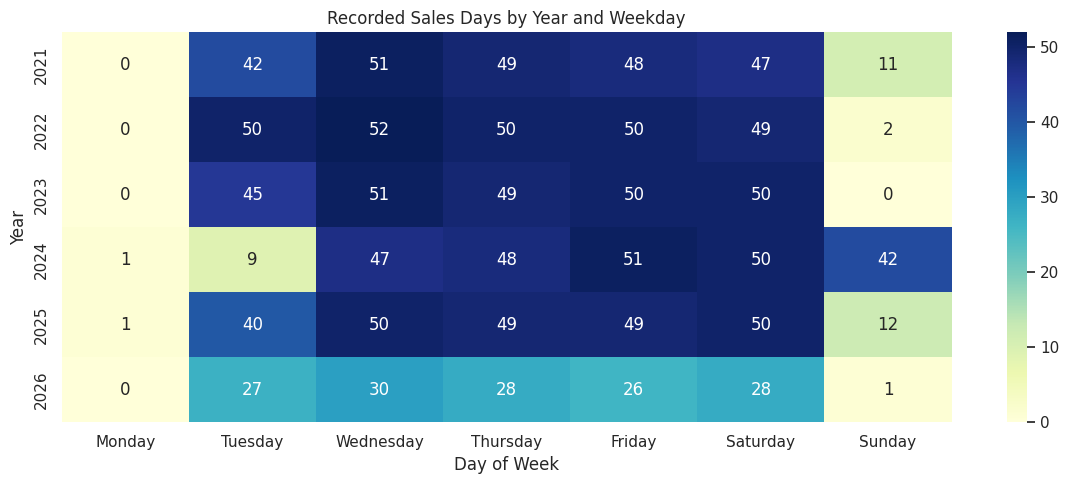

In [ ]:

# Check weekday sales recording patterns by year

check = sales_df.copy()
check["date"] = pd.to_datetime(check["date"])

check["year"] = check["date"].dt.year
check["weekday"] = check["date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

yearly_counts = pd.crosstab(
    check["year"],
    check["weekday"]
).reindex(columns=weekday_order, fill_value=0)

print("Number of recorded sales days by year and weekday:")
display(yearly_counts)

plt.figure(figsize=(12, 5))

sns.heatmap(
    yearly_counts,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Recorded Sales Days by Year and Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


1. Key findings
Period	Main observation
2021–2023	Almost no Sunday records and no Monday records. Tuesday–Saturday are consistently represented.
2024	Major change: 42 Sundays recorded, but only 9 Tuesdays.
2025	Returns closer to the 2021–2023 pattern, with 40 Tuesdays and 12 Sundays.
2026	Similar to 2022–2023, but only partial-year data through July.
The most interesting finding is 2024, where Tuesday and Sunday coverage almost reverse.
This is unlikely to be caused by ordinary German Sunday trading restrictions alone.

The sales dataset exhibits systematic data missing across weekdays, with Mondays almost entirely absent and a notable shift from Tuesday to Sunday observations in 2024. This suggests a possible change in reporting practices or data-generation processes. Missing dates are therefore retained as missing rather than assumed to represent zero sales.

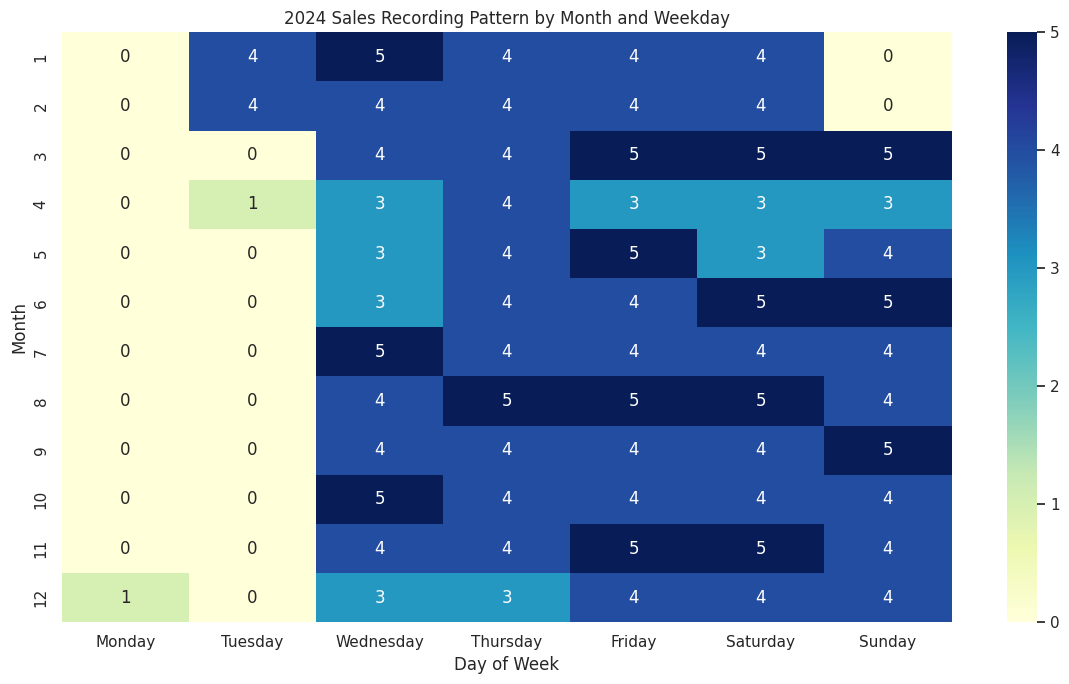

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
month,,,,,,,
1,0,4,5,4,4,4,0
2,0,4,4,4,4,4,0
3,0,0,4,4,5,5,5
4,0,1,3,4,3,3,3
5,0,0,3,4,5,3,4
6,0,0,3,4,4,5,5
7,0,0,5,4,4,4,4
8,0,0,4,5,5,5,4
9,0,0,4,4,4,4,5


In [ ]:

# Investigate weekday recording patterns by month in 2024

sales_2024 = sales_df.copy()
sales_2024["date"] = pd.to_datetime(sales_2024["date"])

sales_2024 = sales_2024[
    sales_2024["date"].dt.year == 2024
].copy()

sales_2024["month"] = sales_2024["date"].dt.month
sales_2024["weekday"] = sales_2024["date"].dt.day_name()

monthly_weekday = pd.crosstab(
    sales_2024["month"],
    sales_2024["weekday"]
).reindex(
    index=range(1, 13),
    columns=[
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ],
    fill_value=0
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    monthly_weekday,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("2024 Sales Recording Pattern by Month and Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

display(monthly_weekday)


Observable Changes -
- January–February: All Tuesdays are represented, while Sundays are absent.
- March: Tuesday records disappear, and all five Sundays are represented.
- April: One Tuesday appears, but the new pattern largely continues.
- May–December: Tuesdays are absent, while Sundays are consistently represented.
This strongly suggests that the recording schedule changed around March 2024.

Exploratory analysis identified a structural change in the temporal coverage of the sales dataset. Between March and December 2024, Tuesday observations were largely absent while Sunday observations became frequent, contrasting with the recording pattern observed in other years. This irregularity may reflect changes in reporting or data collection practices and must be considered when interpreting seasonality and constructing forecasting features.

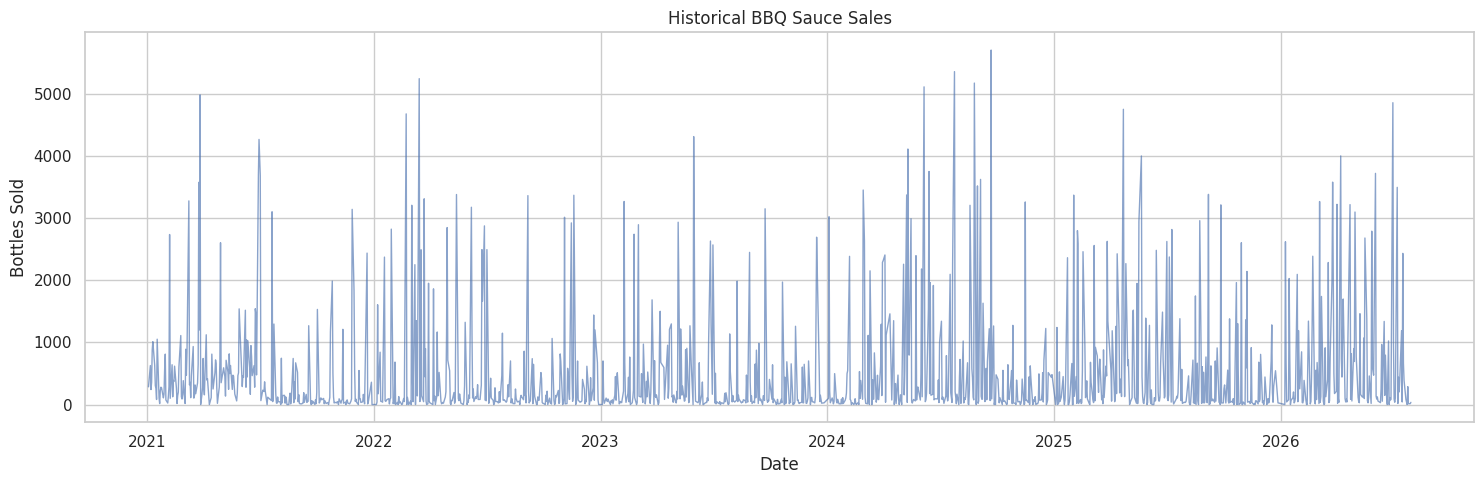

In [ ]:
# Exploring the sales data
plt.figure(figsize=(15, 5))

plt.plot(
    df["date"],
    df["amount"],
    alpha=0.65,
    linewidth=1
)

plt.title("Historical BBQ Sauce Sales")
plt.xlabel("Date")
plt.ylabel("Bottles Sold")
plt.tight_layout()
plt.show()


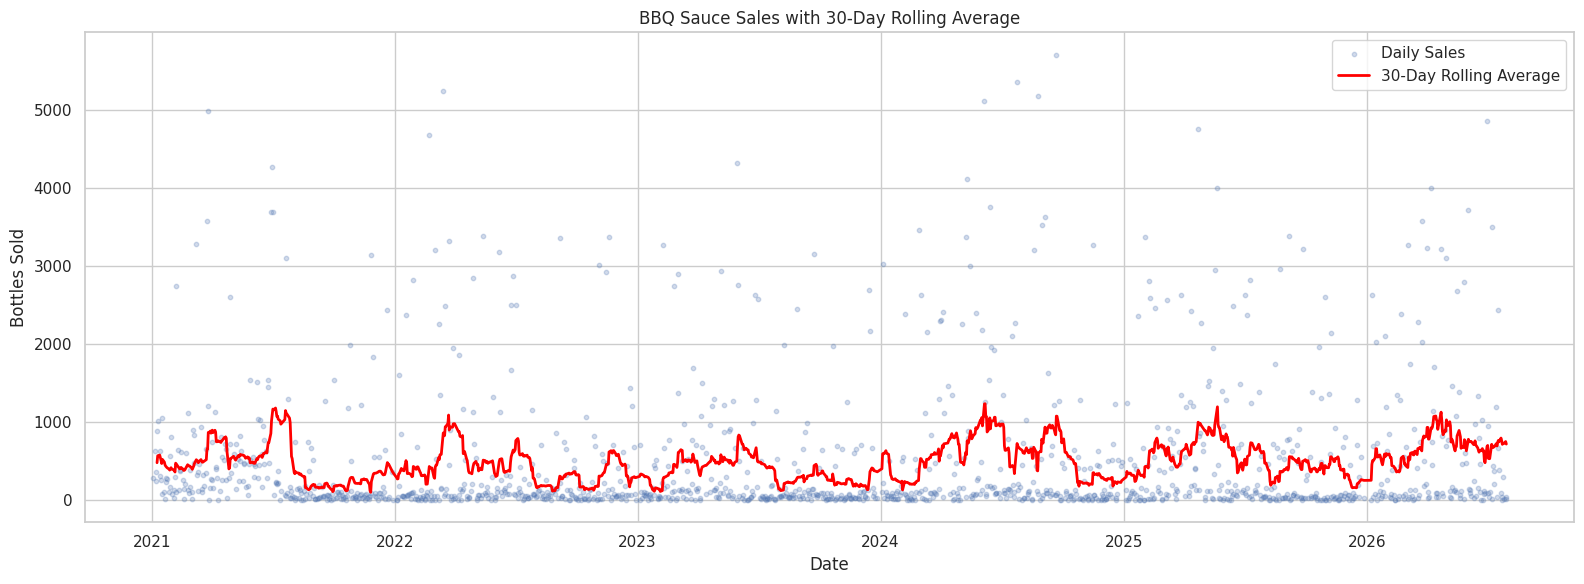

In [ ]:
# Improved Cell 9 — Sales trend with rolling average
# Use calendar dates as the index
sales_ts = df.set_index("date")["amount"].sort_index()

# Calculate a 30-calendar-day rolling average
# using only available observations
rolling_mean = sales_ts.rolling("30D", min_periods=5).mean()

plt.figure(figsize=(16, 6))

plt.scatter(
    sales_ts.index,
    sales_ts.values,
    alpha=0.25,
    s=10,
    label="Daily Sales"
)

plt.plot(
    rolling_mean.index,
    rolling_mean.values,
    color="red",
    linewidth=2,
    label="30-Day Rolling Average"
)

plt.title("BBQ Sauce Sales with 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Bottles Sold")
plt.legend()
plt.tight_layout()
plt.show()


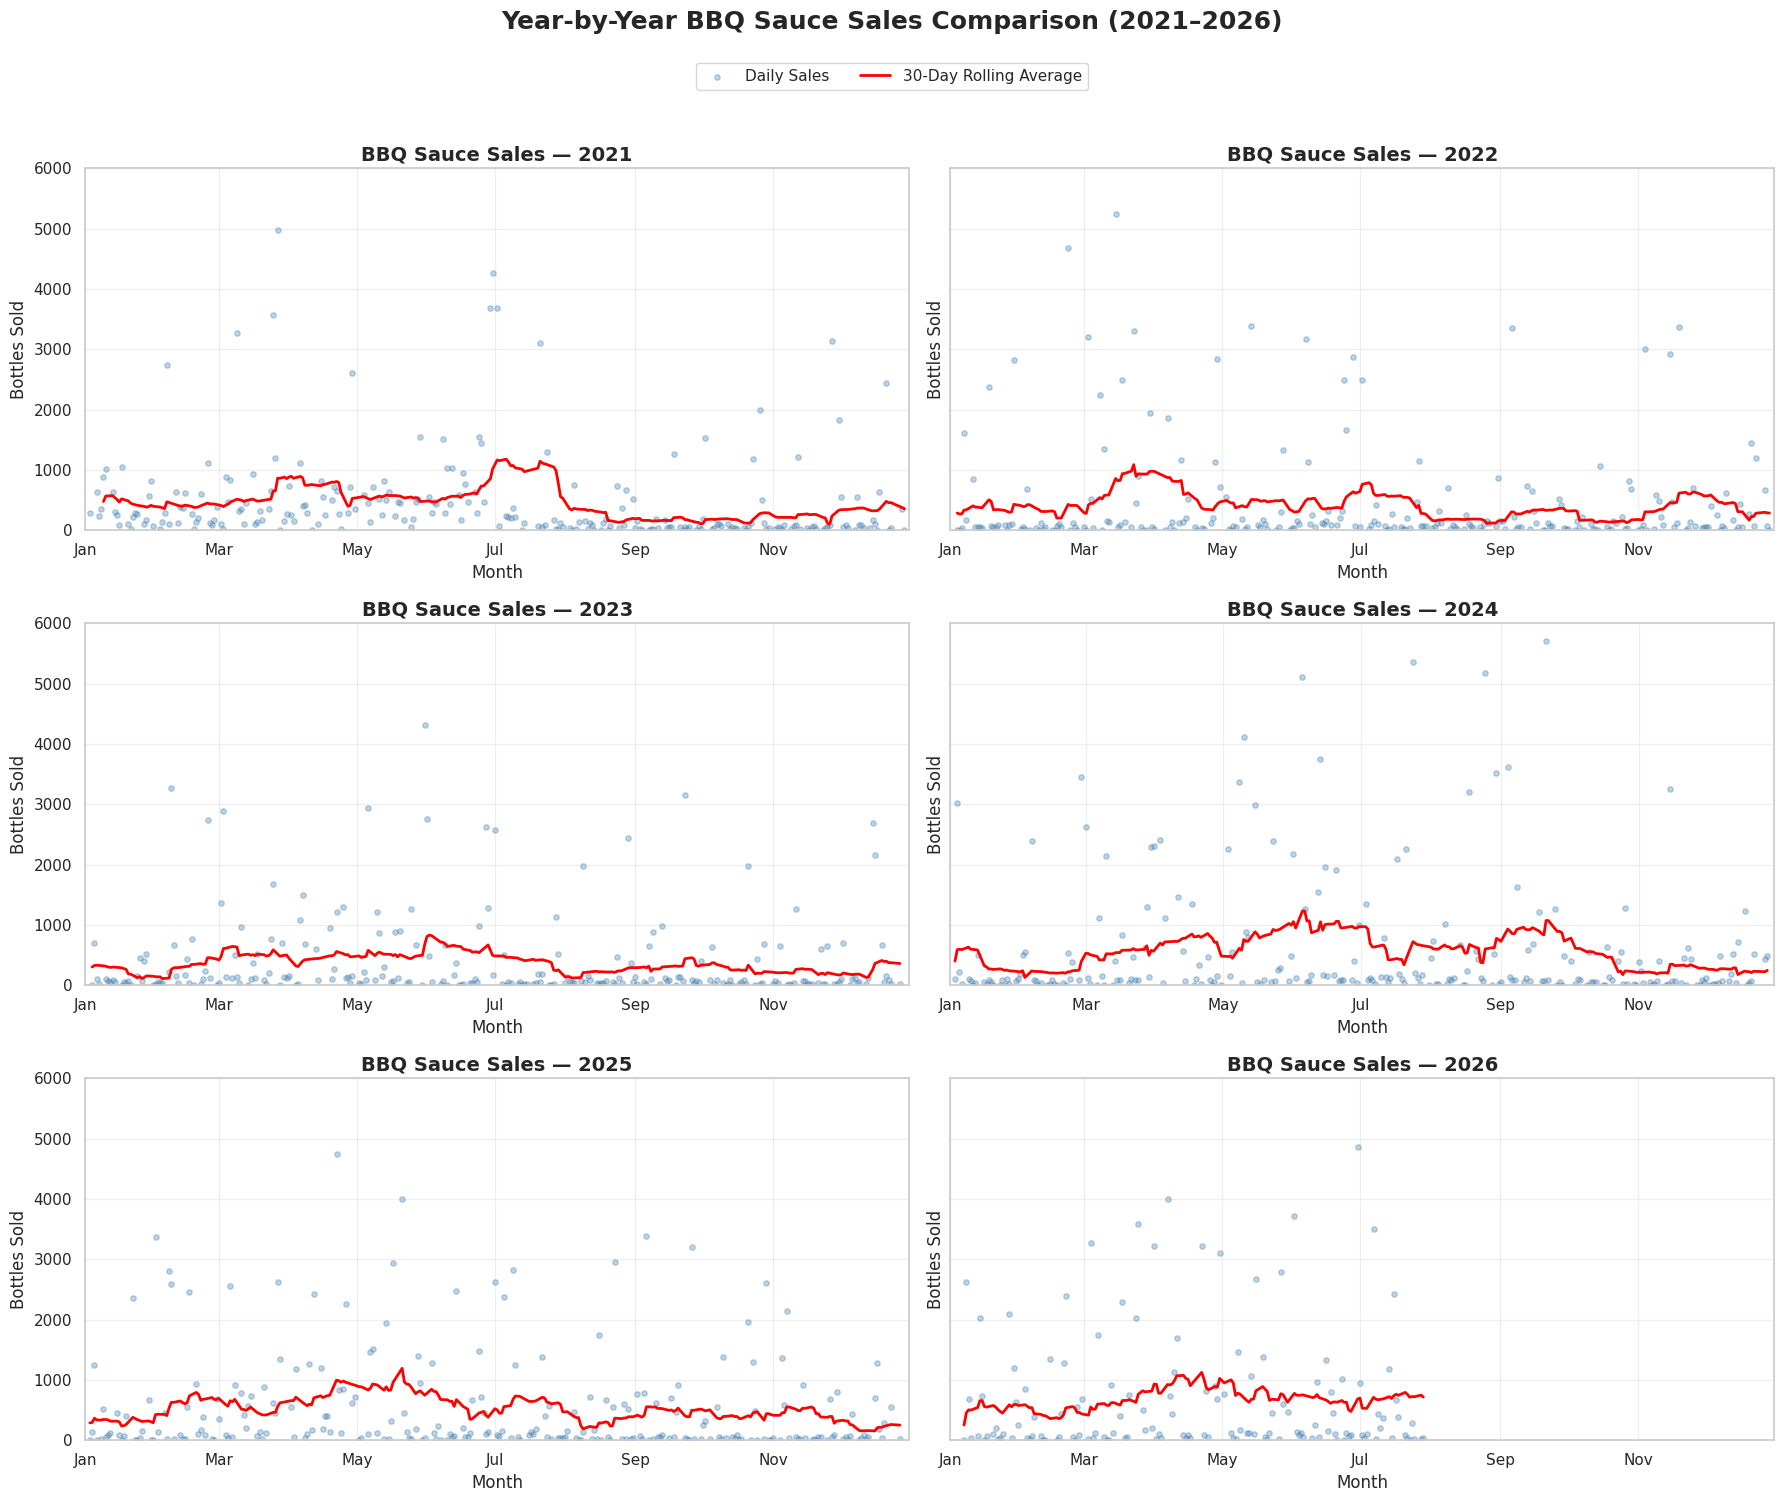

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Prepare time series
sales_ts = (
    df.set_index("date")["amount"]
    .sort_index()
)

# 30-calendar-day rolling average
rolling_mean = sales_ts.rolling(
    "30D", min_periods=5
).mean()

# Create 6 plots (3 rows x 2 columns)
fig, axes = plt.subplots(
    3, 2, figsize=(18, 15),
    sharey=True
)

axes = axes.flatten()

years = range(2021, 2027)

# Consistent Y-axis for comparison
y_max = np.ceil(sales_ts.max() / 1000) * 1000

for i, year in enumerate(years):

    ax = axes[i]

    # Select observations for this year
    yearly_sales = sales_ts[
        sales_ts.index.year == year
    ]

    yearly_rolling = rolling_mean[
        rolling_mean.index.year == year
    ]

    # Daily sales scatterplot
    ax.scatter(
        yearly_sales.index,
        yearly_sales.values,
        color="steelblue",
        alpha=0.35,
        s=15,
        label="Daily Sales"
    )

    # 30-day rolling average
    ax.plot(
        yearly_rolling.index,
        yearly_rolling.values,
        color="red",
        linewidth=2,
        label="30-Day Rolling Average"
    )

    ax.set_title(
        f"BBQ Sauce Sales — {year}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Bottles Sold")
    ax.set_xlabel("Month")

    # Show January–December on every plot
    ax.set_xlim(
        pd.Timestamp(f"{year}-01-01"),
        pd.Timestamp(f"{year}-12-31")
    )

    ax.xaxis.set_major_locator(
        plt.matplotlib.dates.MonthLocator(interval=2)
    )

    ax.xaxis.set_major_formatter(
        plt.matplotlib.dates.DateFormatter("%b")
    )

    ax.set_ylim(0, y_max)
    ax.grid(alpha=0.3)

# Single legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.97)
)

plt.suptitle(
    "Year-by-Year BBQ Sauce Sales Comparison (2021–2026)",
    fontsize=18,
    fontweight="bold",
    y=1.0
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


1. Observations by year
*   2021 - Peaks around April and July, followed by a significant decline in August–September.
*   2022 - Strongest sustained peak around March–April, with another smaller increase around July.
*   2023 - Relatively moderate sales throughout spring, peaking around June, followed by lower sales in August.
*   2024 - High average sales from May–July, with another substantial peak around September.
*   2025 - Strong sales during February–June, with the highest rolling average around May.
*   2026 - Sales increase from January through April–May, followed by moderate levels through July.

The year-by-year analysis reveals recurring periods of increased BBQ sauce sales during spring and early summer, suggesting potential annual seasonality. However, the timing and magnitude of these increases vary across years. The 2024 series displays a distinctive pattern, including elevated sales during September. Extreme sales spikes are present throughout the observation period. These findings support further investigation of calendar-based seasonal features and weather-related predictors, while accounting for irregular recording schedules.




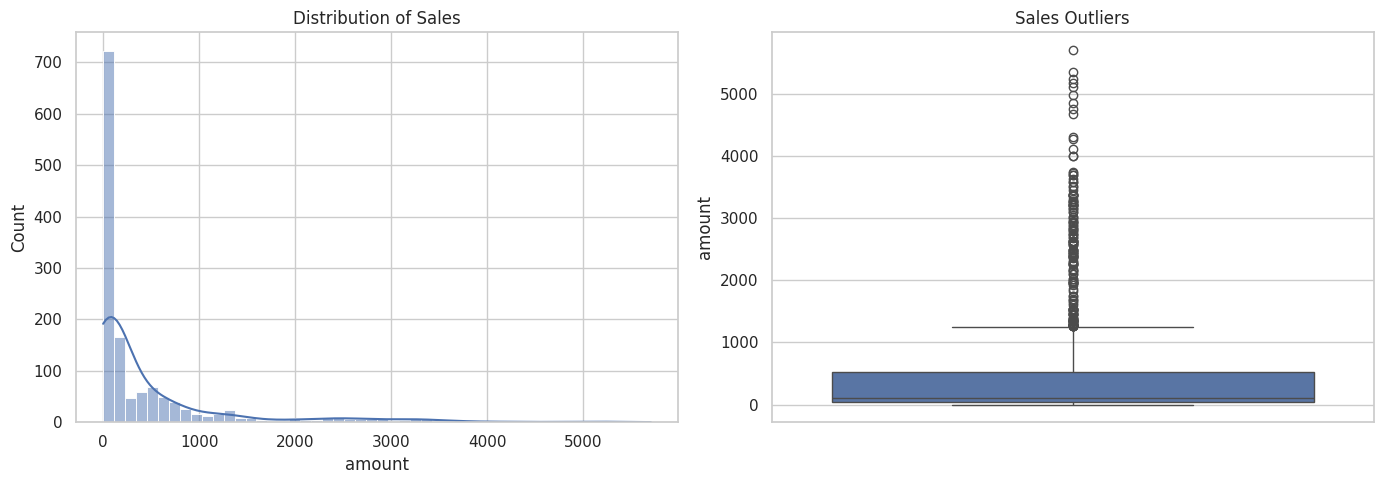

Upper outlier threshold: 1255.0
Number of high outliers: 163


,date,amount
925,2024-09-21,5703
882,2024-07-24,5356
298,2022-03-15,5243
906,2024-08-25,5172
848,2024-06-05,5111
60,2021-03-27,4982
1363,2026-06-30,4856
1069,2025-04-22,4750
283,2022-02-22,4676
601,2023-05-31,4311


In [ ]:
# 10. Sales distribution and Outliers

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="amount",
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Sales")

sns.boxplot(
    data=df,
    y="amount",
    ax=axes[1]
)
axes[1].set_title("Sales Outliers")

plt.tight_layout()
plt.show()

Q1 = df["amount"].quantile(0.25)
Q3 = df["amount"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

outliers = df[df["amount"] > upper_bound]

print("Upper outlier threshold:", round(upper_bound, 2))
print("Number of high outliers:", len(outliers))

display(
    outliers[["date", "amount"]]
    .sort_values("amount", ascending=False)
    .head(15)
)


The histogram shows:
- A very large concentration of observations near zero.
- Most recorded sales values are relatively low.
- The frequency of observations decreases as sales increase.
- A long right tail extends beyond 5,000 bottles.

The boxplot confirms that the dataset contains numerous high-value outliers.
* Lower quartile (Q1) - Near 0–50 bottles
* Median - Around 100 bottles
* Upper quartile (Q3) - Around 500 bottles
* Upper outlier threshold - Approximately 1,250 bottles
* Maximum observed sales - Approximately 5,700 bottles

In [ ]:
# 10B - Sales Distribution Stats

from scipy.stats import skew

sales_values = df["amount"]

Q1 = sales_values.quantile(0.25)
Q3 = sales_values.quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

summary = pd.DataFrame({
    "Metric": [
        "Mean", "Median", "Standard Deviation",
        "Skewness", "Minimum", "Maximum",
        "25th Percentile", "75th Percentile",
        "Outlier Threshold", "Number of High Outliers",
        "Percentage of High Outliers",
        "Zero Sales Observations"
    ],
    "Value": [
        sales_values.mean(),
        sales_values.median(),
        sales_values.std(),
        skew(sales_values),
        sales_values.min(),
        sales_values.max(),
        Q1,
        Q3,
        upper_bound,
        (sales_values > upper_bound).sum(),
        (sales_values > upper_bound).mean() * 100,
        (sales_values == 0).sum()
    ]
})

display(summary.round(2))


,Metric,Value
0,Mean,483.72
1,Median,105.00
2,Standard Deviation,860.14
3,Skewness,2.78
4,Minimum,0.00
5,Maximum,5703.00
6,25th Percentile,35.00
7,75th Percentile,523.00
8,Outlier Threshold,1255.00
9,Number of High Outliers,163.00


Descriptive statistics reveal that BBQ sauce sales exhibit substantial positive skewness (2.78), with a mean of 483.72 bottles and a considerably lower median of 105 bottles. The standard deviation of 860.14 indicates high variability in recorded sales. Using the 1.5 × IQR criterion, 163 observations (11.77%) were identified as high-value outliers, while 115 observations recorded zero sales. These findings indicate a highly uneven sales distribution and suggest that forecasting models should be evaluated using metrics that account for both typical demand and extreme sales events.

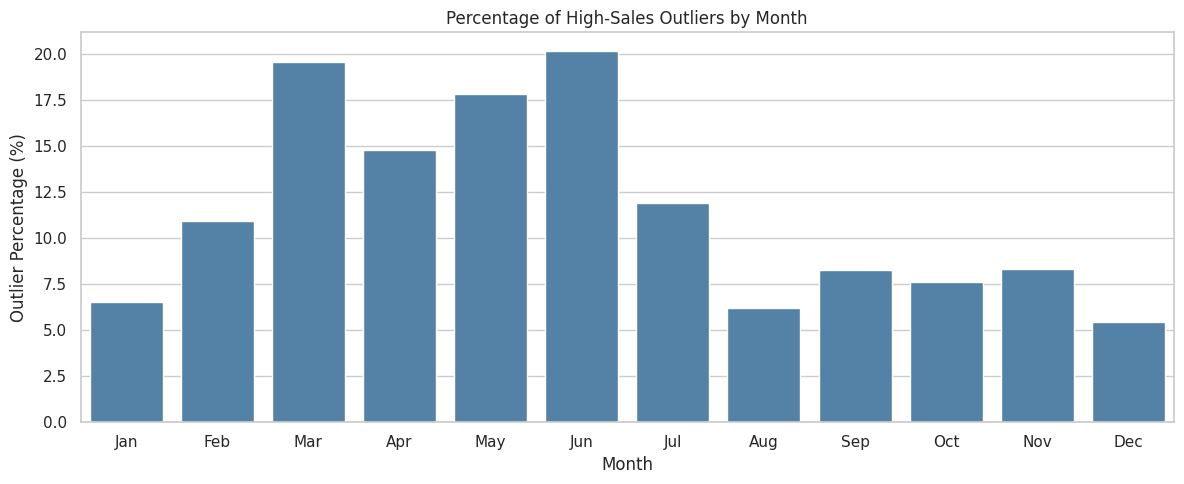

,month,sum,count,outlier_percentage
0,1,8,123,6.50
1,2,13,119,10.92
2,3,26,133,19.55
3,4,17,115,14.78
4,5,21,118,17.80
5,6,25,124,20.16
6,7,15,126,11.90
7,8,7,113,6.19
8,9,9,109,8.26
9,10,8,105,7.62


In [ ]:
# 10C Outlier Frequency by Month


# Create month column from date
df["month"] = pd.to_datetime(df["date"]).dt.month

# Calculate outlier threshold
Q1 = df["amount"].quantile(0.25)
Q3 = df["amount"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

# Flag high sales outliers
df["is_outlier"] = df["amount"] > upper_bound

# Calculate monthly outlier frequency
monthly_outliers = (
    df.groupby("month")["is_outlier"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

monthly_outliers["outlier_percentage"] = (
    monthly_outliers["mean"] * 100
)

# Plot monthly outlier percentages
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_outliers,
    x="month",
    y="outlier_percentage",
    color="steelblue"
)

plt.title("Percentage of High-Sales Outliers by Month")
plt.xlabel("Month")
plt.ylabel("Outlier Percentage (%)")
plt.xticks(
    ticks=range(12),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()

# Display summary table
display(
    monthly_outliers[
        ["month", "sum", "count", "outlier_percentage"]
    ].round(2)
)


Monthly outlier analysis reveals a distinct seasonal concentration of high-sales observations. June exhibits the highest outlier frequency (20.16%), followed by March (19.55%) and May (17.80%). Conversely, December (5.43%) and August (6.19%) exhibit comparatively low outlier frequencies. These results suggest that unusually high BBQ sauce sales occur more frequently during spring and early summer. However, the relationship between these seasonal patterns and meteorological conditions requires further investigation.

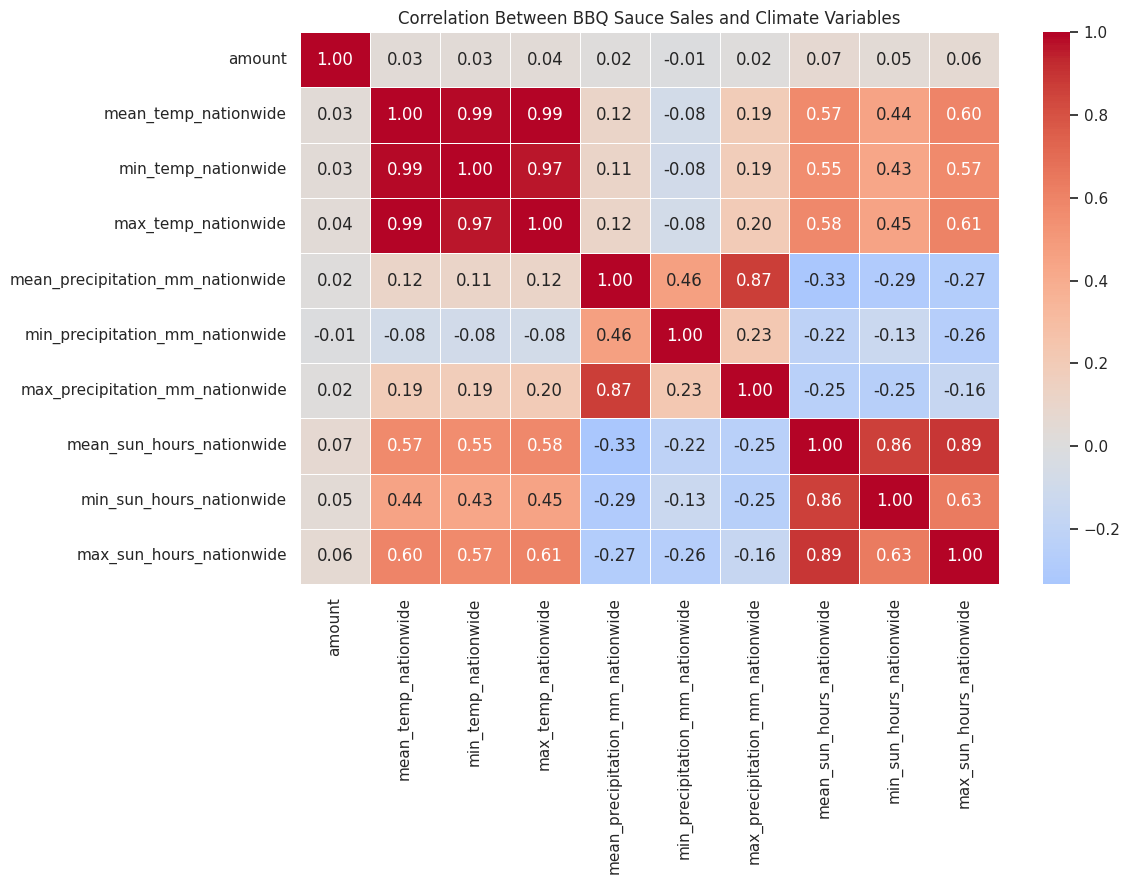

In [ ]:
# 11. Correlation Matrix


# Weather variables and sales only
weather_cols = [
    col for col in df.columns
    if "nationwide" in col
]

correlation_cols = ["amount"] + weather_cols

corr_weather = df[correlation_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_weather,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between BBQ Sauce Sales and Climate Variables")
plt.tight_layout()
plt.show()


The correlation analysis identifies negligible same-day linear relationships between BBQ sauce sales and nationwide climate conditions. Mean sunshine hours exhibit the highest positive correlation with sales (r = 0.07). Strong correlations among temperature and sunshine measurements indicate redundancy between several meteorological predictors. Further investigation of nonlinear relationships, lagged effects, and seasonal interactions is required to assess the predictive value of climate variables.

Pearson vs Spearman Correlation with BBQ Sauce Sales:


,Pearson,Spearman,Pearson Strength,Spearman Strength
mean_sun_hours_nationwide,0.065,0.116,0.065,0.116
min_sun_hours_nationwide,0.045,0.109,0.045,0.109
max_sun_hours_nationwide,0.059,0.096,0.059,0.096
min_temp_nationwide,0.032,0.043,0.032,0.043
mean_temp_nationwide,0.034,0.041,0.034,0.041
max_temp_nationwide,0.036,0.038,0.036,0.038
mean_precipitation_mm_nationwide,0.015,-0.029,0.015,0.029
max_precipitation_mm_nationwide,0.016,-0.018,0.016,0.018
min_precipitation_mm_nationwide,-0.006,0.003,0.006,0.003


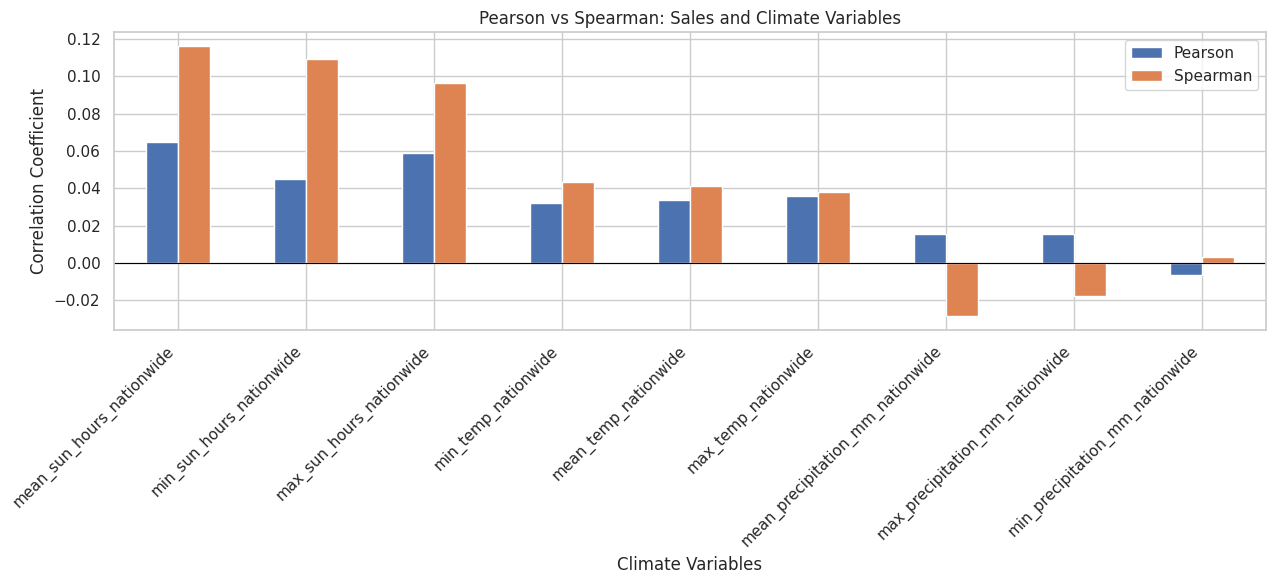

In [ ]:
# Cell 12: Pearson vs Spearman Correlation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select sales and climate variables
weather_cols = [
    col for col in df.columns
    if "nationwide" in col
]

numeric_df = df[["amount"] + weather_cols].copy()

# Calculate Pearson correlations
pearson = numeric_df.corr(method="pearson")["amount"]

# Calculate Spearman correlations
spearman = numeric_df.corr(method="spearman")["amount"]

# Create comparison table
comparison = pd.DataFrame({
    "Pearson": pearson,
    "Spearman": spearman
}).drop(index="amount")

# Calculate absolute correlation strength
comparison["Pearson Strength"] = comparison["Pearson"].abs()
comparison["Spearman Strength"] = comparison["Spearman"].abs()

# Sort by Spearman strength
comparison = comparison.sort_values(
    "Spearman Strength",
    ascending=False
)

print("Pearson vs Spearman Correlation with BBQ Sauce Sales:")
display(comparison.round(3))

# Visualize comparison
comparison[["Pearson", "Spearman"]].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Pearson vs Spearman: Sales and Climate Variables")
plt.xlabel("Climate Variables")
plt.ylabel("Correlation Coefficient")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


The comparison of Pearson and Spearman correlation coefficients indicates weak associations between BBQ sauce sales and meteorological variables. Sunshine exhibits the strongest positive relationship, with mean sunshine hours producing a Pearson coefficient of 0.065 and a Spearman coefficient of 0.116. The higher Spearman coefficient suggests that rank-based associations may capture aspects of the relationship not reflected in linear correlation, potentially due to skewness or extreme sales observations. Temperature and precipitation demonstrate negligible correlations under both methods. These findings motivate further investigation of nonlinear relationships, lagged weather effects, and seasonal interactions.

Monthly BBQ Sauce Sales Statistics:


,mean,median,std,count
Jan,341.26,88.0,609.06,123
Feb,465.46,99.0,875.32,119
Mar,733.10,199.0,1061.23,133
Apr,660.95,281.0,895.61,115
May,649.47,187.0,974.86,118
Jun,708.72,176.5,1068.96,124
Jul,462.79,88.5,902.27,126
Aug,354.79,79.0,769.22,113
Sep,405.73,67.0,894.88,109
Oct,268.10,53.0,499.06,105


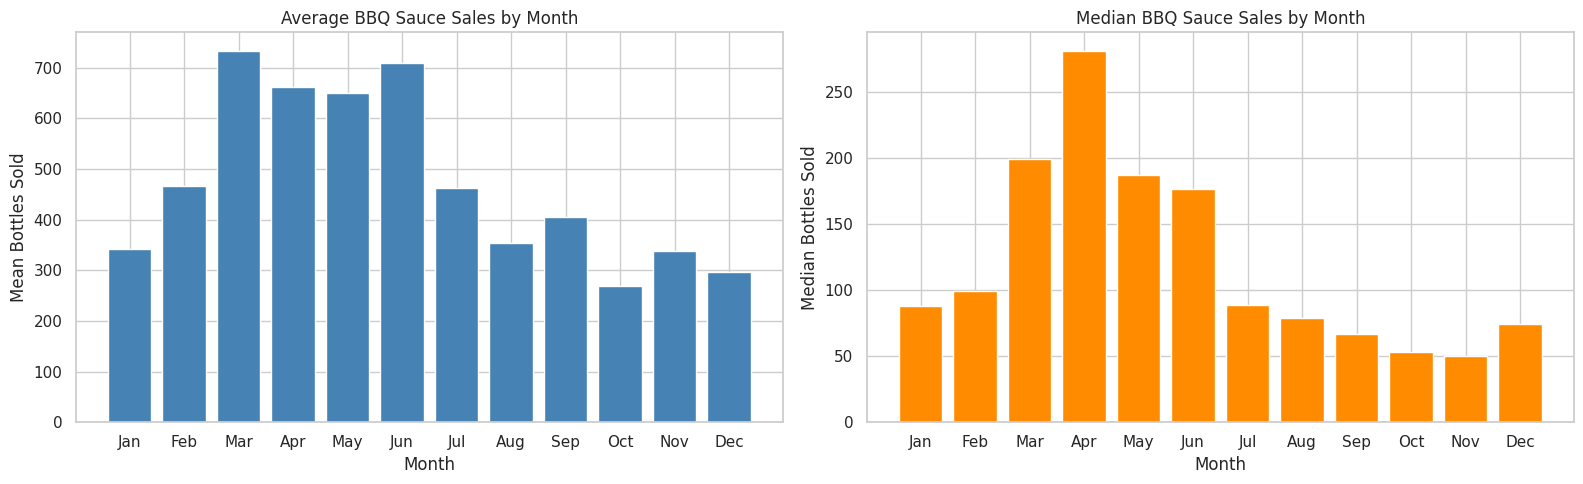

In [ ]:

# Cell 13: Monthly Sales Seasonality

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare date features
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Monthly statistics
monthly_stats = (
    df.groupby("month")["amount"]
    .agg(["mean", "median", "std", "count"])
    .reindex(range(1, 13))
)

monthly_stats.index = month_names

print("Monthly BBQ Sauce Sales Statistics:")
display(monthly_stats.round(2))

# Compare mean and median sales
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(
    month_names,
    monthly_stats["mean"],
    color="steelblue"
)

axes[0].set_title("Average BBQ Sauce Sales by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean Bottles Sold")

axes[1].bar(
    month_names,
    monthly_stats["median"],
    color="darkorange"
)

axes[1].set_title("Median BBQ Sauce Sales by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Median Bottles Sold")

plt.tight_layout()
plt.show()


Monthly sales analysis reveals a pronounced seasonal pattern, with higher sales generally observed between March and June. March records the highest mean sales (733.10 bottles), while April exhibits the highest median (281 bottles), indicating relatively strong typical demand during spring. Conversely, October records the lowest mean sales (268.10 bottles), and November has the lowest median (50 bottles). The substantial differences between monthly means and medians confirm that extreme sales observations influence average demand throughout the year. High standard deviations, particularly in March and June, further indicate considerable sales variability. These findings suggest that calendar-based seasonal features may be important for forecasting, although the consistency of these patterns across individual years requires further investigation.

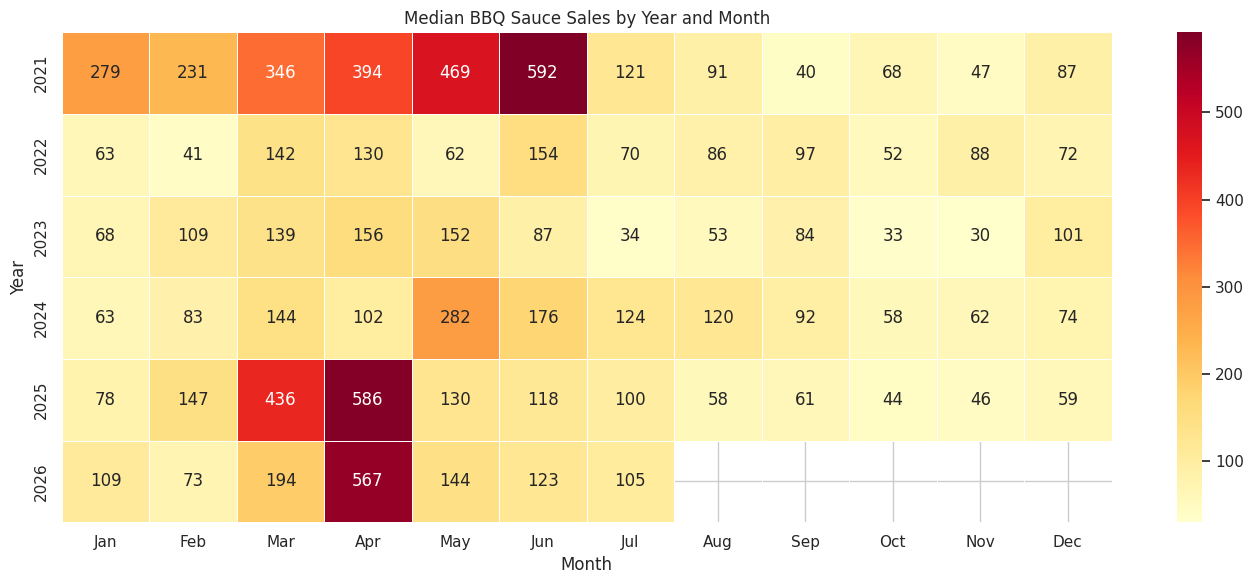

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2021,279.0,231.0,346.0,394.0,469.0,592.0,121.0,91.0,40.0,68.5,47.0,87.0
2022,63.0,41.0,141.5,129.5,62.0,154.0,70.0,86.0,97.0,52.0,87.5,72.5
2023,68.0,109.0,139.0,156.0,152.0,87.0,34.0,53.0,83.5,33.0,29.5,101.0
2024,63.0,83.0,144.0,102.0,282.0,176.0,124.0,120.0,92.0,58.0,61.5,74.0
2025,78.0,147.0,435.5,586.5,130.0,118.5,99.5,57.5,61.0,44.0,46.0,59.0
2026,109.0,73.0,194.0,567.0,143.5,123.0,105.0,NaN,NaN,NaN,NaN,NaN


In [ ]:

# Cell 14A: Year-by-Year Monthly Sales Heatmap

# Calculate median sales by year and month
year_month_sales = (
    df.groupby(["year", "month"])["amount"]
    .median()
    .unstack()
    .reindex(columns=range(1, 13))
)

year_month_sales.columns = month_names

plt.figure(figsize=(14, 6))

sns.heatmap(
    year_month_sales,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Median BBQ Sauce Sales by Year and Month")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

display(year_month_sales.round(2))


The year-by-year monthly median sales analysis reveals a recurring seasonal pattern, with the highest monthly median sales occurring between March and June in every observed year. April emerges as a particularly important month, recording the highest median sales in 2023, 2025, and 2026. Nevertheless, the magnitude and timing of seasonal peaks vary considerably across years. June 2021 exhibits the highest monthly median (592 bottles), followed by April 2025 (586.5 bottles). The 2024 series also displays a distinctive pattern, potentially influenced by changes in sales recording coverage. Overall, the findings suggest that calendar-based seasonal variables may be valuable forecasting features, although further analysis is required to establish their predictive contribution.

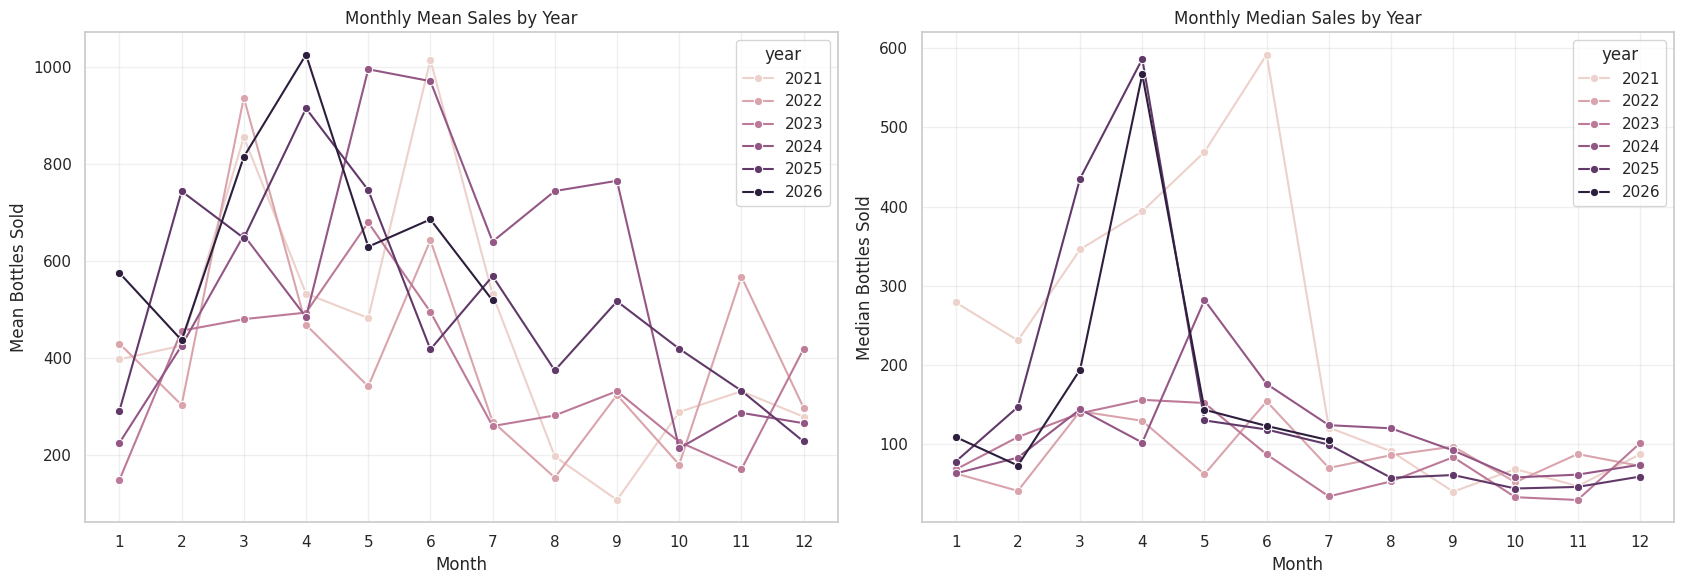

In [ ]:

# Cell 14B: Compare Monthly Sales Trends Across Years

monthly_yearly = (
    df.groupby(["year", "month"])["amount"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.lineplot(
    data=monthly_yearly,
    x="month",
    y="mean",
    hue="year",
    marker="o",
    estimator=None,
    ax=axes[0]
)

axes[0].set_title("Monthly Mean Sales by Year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean Bottles Sold")
axes[0].set_xticks(range(1, 13))
axes[0].grid(alpha=0.3)

sns.lineplot(
    data=monthly_yearly,
    x="month",
    y="median",
    hue="year",
    marker="o",
    estimator=None,
    ax=axes[1]
)

axes[1].set_title("Monthly Median Sales by Year")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Median Bottles Sold")
axes[1].set_xticks(range(1, 13))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


The comparison of monthly mean and median sales across years reveals recurring seasonal patterns, with higher sales generally concentrated between March and June. All observed years exhibit their highest monthly median within this period, although the timing and magnitude of the peaks vary. Monthly mean sales display greater volatility than median sales, consistent with the strongly right-skewed distribution and frequent high-value outliers identified earlier. Sales generally decline during late summer and autumn, suggesting potential seasonal demand effects. Nevertheless, irregular sales recording schedules and year-to-year variability require consideration when interpreting these patterns.

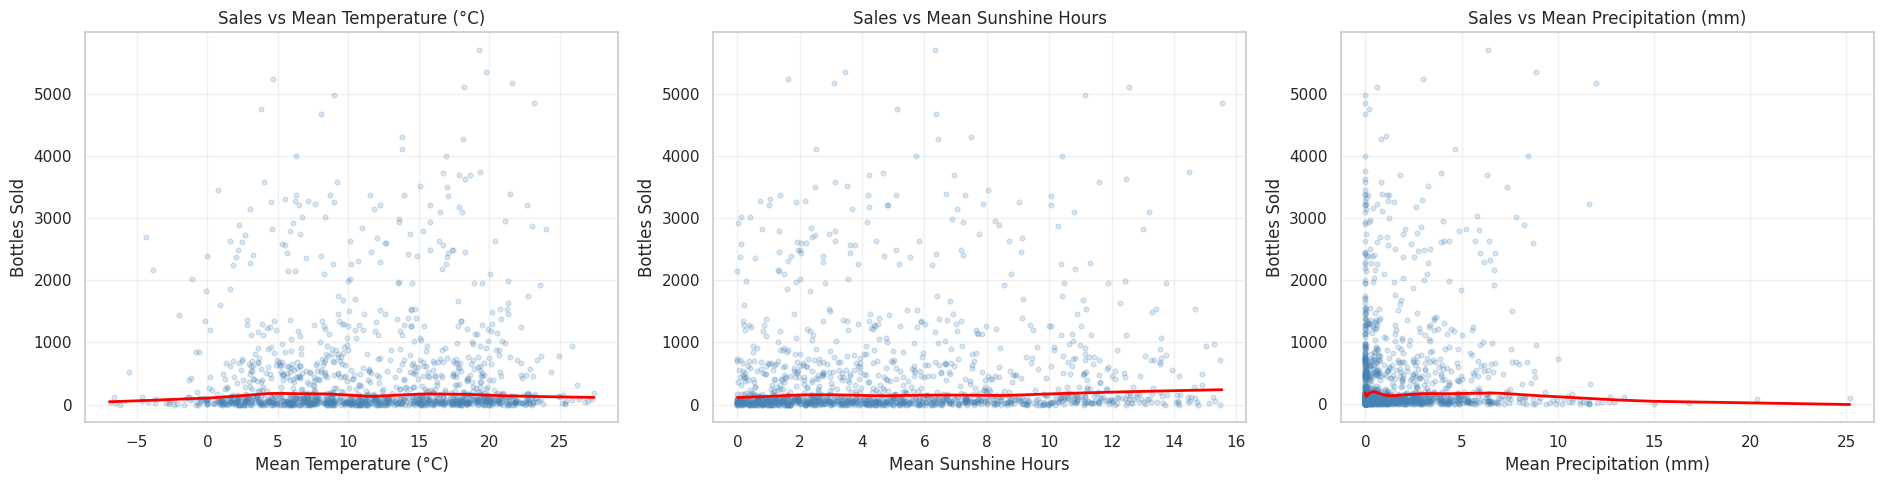

In [ ]:

# Cell 15: Nonlinear Weather Relationships

import statsmodels.api as sm

weather_features = [
    "mean_temp_nationwide",
    "mean_sun_hours_nationwide",
    "mean_precipitation_mm_nationwide"
]

weather_labels = [
    "Mean Temperature (°C)",
    "Mean Sunshine Hours",
    "Mean Precipitation (mm)"
]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, feature, label in zip(
    axes, weather_features, weather_labels
):

    valid = df[[feature, "amount"]].dropna()
    x = valid[feature].to_numpy()
    y = valid["amount"].to_numpy()

    # Scatterplot
    ax.scatter(
        x, y,
        alpha=0.2,
        s=12,
        color="steelblue"
    )

    # LOWESS smoothing
    lowess_result = sm.nonparametric.lowess(
        y, x, frac=0.3, return_sorted=True
    )

    ax.plot(
        lowess_result[:, 0],
        lowess_result[:, 1],
        color="red",
        linewidth=2
    )

    ax.set_title(f"Sales vs {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Bottles Sold")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Nonlinear exploratory analysis using LOWESS smoothing reveals limited evidence of strong relationships between same-day climate conditions and BBQ sauce sales. Sunshine exhibits a weak positive trend, whereas temperature and precipitation show relatively flat relationships. Large sales observations occur across diverse weather conditions, suggesting that meteorological variables alone do not explain extreme demand fluctuations. The analysis also highlights uncertainty surrounding the interpretation of sales dates, particularly given the irregular weekday recording patterns. These issues should be considered before constructing lagged forecasting features.

,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Shift,,,,,,,
-2,281,273,274,274,68,2,213
-1,213,281,273,274,274,68,2
0,2,213,281,273,274,274,68
1,68,2,213,281,273,274,274
2,274,68,2,213,281,273,274


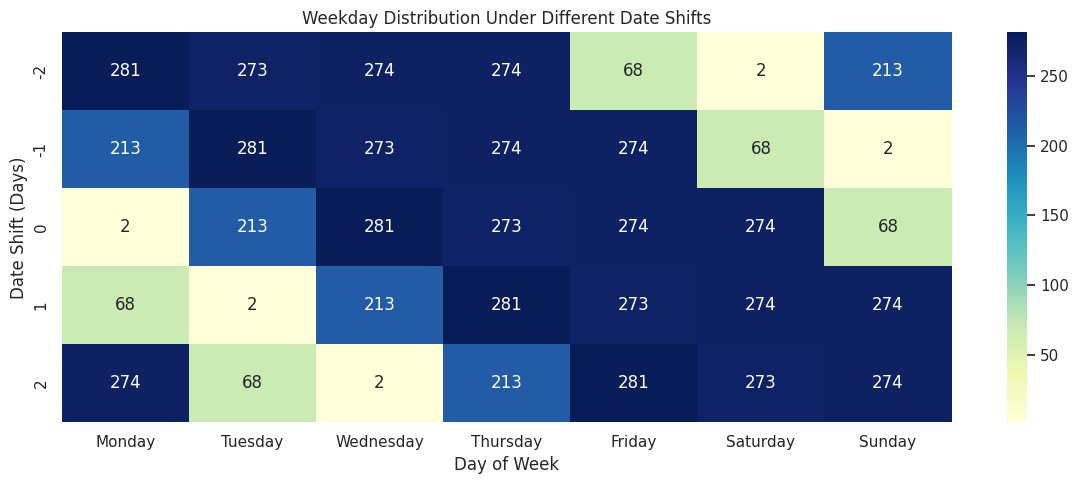

In [ ]:
# 15B - Test Weekday Allignment

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

check = sales_df.copy()
check["date"] = pd.to_datetime(check["date"])

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Compare original and shifted weekday distributions
results = []

for shift in [-2, -1, 0, 1, 2]:
    shifted_dates = check["date"] + pd.Timedelta(days=shift)

    counts = (
        shifted_dates.dt.day_name()
        .value_counts()
        .reindex(weekday_order, fill_value=0)
    )

    results.append({
        "Shift": shift,
        **counts.to_dict()
    })

shift_comparison = pd.DataFrame(results).set_index("Shift")

display(shift_comparison)

plt.figure(figsize=(12, 5))

sns.heatmap(
    shift_comparison,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Weekday Distribution Under Different Date Shifts")
plt.xlabel("Day of Week")
plt.ylabel("Date Shift (Days)")
plt.tight_layout()
plt.show()


In [ ]:
# Checking for German Holiday Sales
!pip install holidays -q


In [ ]:

# Cell 15C: German Public Holiday Analysis

import pandas as pd
import numpy as np
import holidays

# Prepare sales data
holiday_df = sales_df.copy()
holiday_df["date"] = pd.to_datetime(holiday_df["date"]).dt.normalize()

# German public holidays, 2021–2026
# Nationwide holidays only
german_holidays = holidays.Germany(
    years=range(2021, 2027)
)

# Keep holidays observed in all German states
national_holidays = holidays.Germany(
    years=range(2021, 2027),
    subdiv=None
)

# Build nationwide calendar by intersecting all states
states = [
    "BW", "BY", "BE", "BB", "HB", "HH",
    "HE", "MV", "NI", "NW", "RP", "SL",
    "SN", "ST", "SH", "TH"
]

state_calendars = [
    holidays.Germany(years=range(2021, 2027), subdiv=s)
    for s in states
]

common_dates = set(state_calendars[0].keys())

for cal in state_calendars[1:]:
    common_dates &= set(cal.keys())

holiday_lookup = {
    pd.Timestamp(d): national_holidays.get(d, "Public Holiday")
    for d in common_dates
}

# Full date range
all_dates = pd.date_range(
    holiday_df["date"].min(),
    holiday_df["date"].max(),
    freq="D"
)

calendar = pd.DataFrame({"date": all_dates})

calendar["weekday"] = calendar["date"].dt.day_name()
calendar["is_sunday"] = calendar["date"].dt.dayofweek == 6
calendar["holiday_name"] = calendar["date"].map(holiday_lookup)
calendar["is_holiday"] = calendar["holiday_name"].notna()

# Check whether a sales record exists
sales_dates = set(holiday_df["date"])

calendar["has_sales_record"] = calendar["date"].isin(sales_dates)

# Classify closure dates
calendar["expected_closed"] = (
    calendar["is_sunday"] | calendar["is_holiday"]
)

print("Holiday and Sales Recording Summary")

summary = calendar.groupby(
    "expected_closed"
)["has_sales_record"].agg(["sum", "count", "mean"])

display(summary.round(3))

# Show holidays with recorded sales
holiday_sales = calendar[
    calendar["is_holiday"] &
    calendar["has_sales_record"]
]

print("\nPublic holidays with recorded sales:")
display(
    holiday_sales[
        ["date", "weekday", "holiday_name"]
    ]
)

# Show holidays without sales
missing_holiday_sales = calendar[
    calendar["is_holiday"] &
    ~calendar["has_sales_record"]
]

print("\nPublic holidays without sales records:")
display(
    missing_holiday_sales[
        ["date", "weekday", "holiday_name"]
    ]
)


Holiday and Sales Recording Summary


,sum,count,mean
expected_closed,,,
False,1305,1698,0.769
True,80,336,0.238



Public holidays with recorded sales:


,date,weekday,holiday_name
89,2021-04-02,Friday,Good Friday
130,2021-05-13,Thursday,Ascension Day
467,2022-04-15,Friday,Good Friday
508,2022-05-26,Thursday,Ascension Day
824,2023-04-07,Friday,Good Friday
865,2023-05-18,Thursday,Ascension Day
1181,2024-03-29,Friday,Good Friday
1222,2024-05-09,Thursday,Ascension Day
1566,2025-04-18,Friday,Good Friday
1607,2025-05-29,Thursday,Ascension Day



Public holidays without sales records:


,date,weekday,holiday_name
92,2021-04-05,Monday,Easter Monday
118,2021-05-01,Saturday,Labor Day
141,2021-05-24,Monday,Pentecost Monday
273,2021-10-03,Sunday,German Unity Day
356,2021-12-25,Saturday,Christmas Day
357,2021-12-26,Sunday,Second Day of Christmas
363,2022-01-01,Saturday,New Year's Day
470,2022-04-18,Monday,Easter Monday
483,2022-05-01,Sunday,Labor Day
519,2022-06-06,Monday,Pentecost Monday


The comparison of sales recording dates with nationwide German public holidays indicates that recorded sales are substantially less frequent on expected retail closure days (23.8%) than on other days (76.9%). However, Good Friday and Ascension Day consistently contain sales records across all observed years, while several other holidays have no records. This inconsistency suggests that sales dates may reflect reporting conventions or transaction channels that do not strictly follow ordinary German retail opening schedules. Consequently, missing sales dates should not automatically be interpreted as zero sales.

,Shift,Records on Closed Days,Percentage
0,-3,305,22.02
1,-2,245,17.69
2,-1,34,2.45
3,0,80,5.78
4,1,294,21.23
5,2,304,21.95
6,3,302,21.81


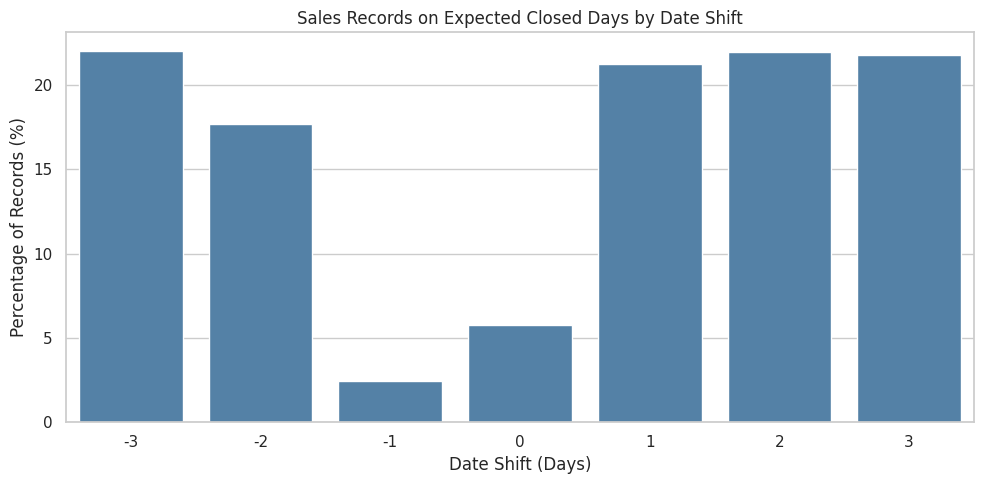

In [ ]:

# Cell 15D: Holiday Alignment Under Date Shifts

shift_results = []

for shift in range(-3, 4):

    shifted_dates = (
        holiday_df["date"] +
        pd.Timedelta(days=shift)
    )

    shifted_calendar = pd.DataFrame({
        "date": shifted_dates
    })

    shifted_calendar["is_sunday"] = (
        shifted_calendar["date"].dt.dayofweek == 6
    )

    shifted_calendar["is_holiday"] = (
        shifted_calendar["date"].isin(holiday_lookup)
    )

    shifted_calendar["expected_closed"] = (
        shifted_calendar["is_sunday"] |
        shifted_calendar["is_holiday"]
    )

    closed_count = shifted_calendar["expected_closed"].sum()

    shift_results.append({
        "Shift": shift,
        "Records on Closed Days": closed_count,
        "Percentage": 100 * closed_count / len(shifted_calendar)
    })

shift_results = pd.DataFrame(shift_results)

display(shift_results.round(2))

# Plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=shift_results,
    x="Shift",
    y="Percentage",
    color="steelblue"
)

plt.title("Sales Records on Expected Closed Days by Date Shift")
plt.xlabel("Date Shift (Days)")
plt.ylabel("Percentage of Records (%)")
plt.tight_layout()
plt.show()


The date-shift analysis indicates that moving sales dates backward by one day reduces the proportion of records falling on expected German retail closure days from approximately 5.7% to 2.4%. This suggests a possible discrepancy between recorded dates and actual transaction dates. However, the evidence is insufficient to confirm a systematic reporting offset, particularly given the changing weekday distribution observed in 2024. The original dates were therefore retained for subsequent analysis.

,sum,count,missing
year,,,
2021,2,8,6
2022,2,9,7
2023,2,9,7
2024,2,9,7
2025,2,9,7
2026,2,6,4


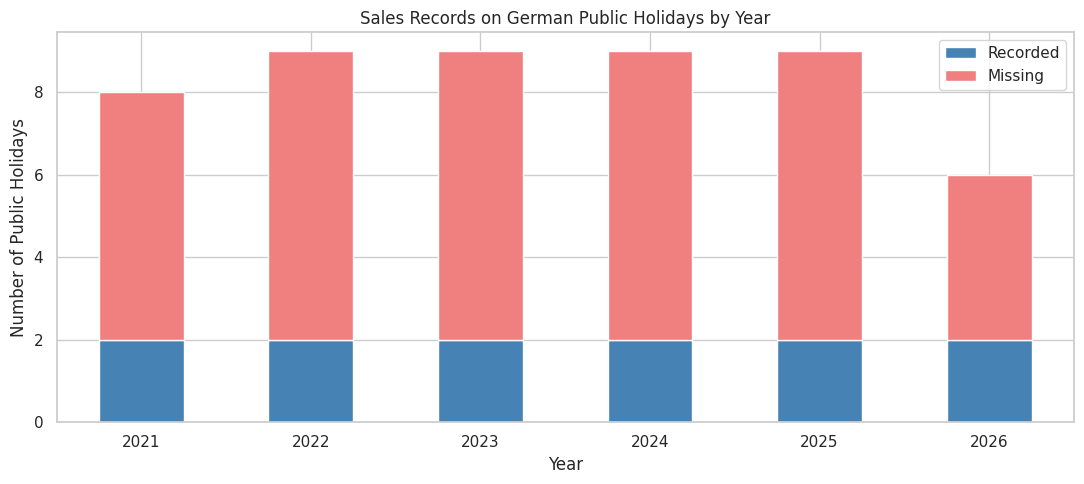

In [ ]:

# Cell 15E: Holiday Sales Recording by Year

calendar["year"] = calendar["date"].dt.year

holiday_yearly = (
    calendar[calendar["is_holiday"]]
    .groupby("year")["has_sales_record"]
    .agg(["sum", "count"])
)

holiday_yearly["missing"] = (
    holiday_yearly["count"] - holiday_yearly["sum"]
)

display(holiday_yearly)

holiday_yearly[["sum", "missing"]].plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    color=["steelblue", "lightcoral"]
)

plt.title("Sales Records on German Public Holidays by Year")
plt.xlabel("Year")
plt.ylabel("Number of Public Holidays")
plt.legend(["Recorded", "Missing"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


The public holiday analysis reveals a consistent recording pattern across the study period. Most nationwide German public holidays have no associated sales records, while Good Friday and Ascension Day consistently contain records in every observed year. This suggests that the availability of sales observations may be influenced by calendar-related reporting practices rather than solely by actual retail activity. Consequently, missing dates should not automatically be interpreted as zero-sales days.

Percentage of Sales Records on Expected Closed Days


Date Shift,-3,-2,-1,0,1,2,3
Year,,,,,,,
2021,22.18,18.55,1.61,5.24,20.16,21.77,21.77
2022,22.13,21.74,2.37,1.58,20.16,21.34,21.74
2023,22.45,20.41,2.45,0.82,21.22,22.86,22.45
2024,21.77,7.26,2.02,17.74,22.58,21.37,20.97
2025,21.12,18.33,3.19,5.58,21.51,22.31,21.51
2026,22.86,21.43,3.57,2.14,22.14,22.14,22.86


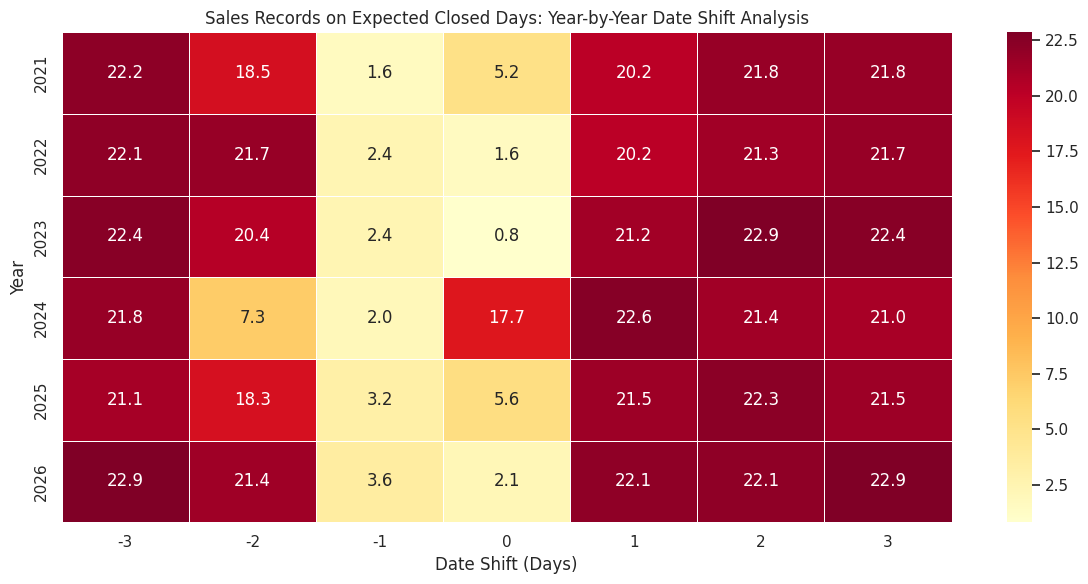


Shift with Fewest Records on Expected Closed Days:


,Year,Date Shift,Percentage
2,2021,-1,1.61
10,2022,0,1.58
17,2023,0,0.82
23,2024,-1,2.02
30,2025,-1,3.19
38,2026,0,2.14


In [ ]:

# Cell 15F: Year-by-Year Date Shift Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results = []

for year in sorted(holiday_df["date"].dt.year.unique()):

    year_data = holiday_df[
        holiday_df["date"].dt.year == year
    ].copy()

    for shift in range(-3, 4):

        shifted_dates = (
            year_data["date"] + pd.Timedelta(days=shift)
        )

        # Sunday or nationwide public holiday
        is_sunday = shifted_dates.dt.dayofweek == 6
        is_holiday = shifted_dates.isin(holiday_lookup)

        expected_closed = is_sunday | is_holiday

        results.append({
            "Year": year,
            "Date Shift": shift,
            "Records on Closed Days": expected_closed.sum(),
            "Total Records": len(year_data),
            "Percentage": expected_closed.mean() * 100
        })

yearly_shift = pd.DataFrame(results)

# Pivot table
shift_pivot = yearly_shift.pivot(
    index="Year",
    columns="Date Shift",
    values="Percentage"
)

print("Percentage of Sales Records on Expected Closed Days")
display(shift_pivot.round(2))

# Heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    shift_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Sales Records on Expected Closed Days: "
    "Year-by-Year Date Shift Analysis"
)

plt.xlabel("Date Shift (Days)")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# Identify best shift for each year
best_shifts = (
    yearly_shift.loc[
        yearly_shift.groupby("Year")["Percentage"].idxmin(),
        ["Year", "Date Shift", "Percentage"]
    ]
    .sort_values("Year")
)

print("\nShift with Fewest Records on Expected Closed Days:")
display(best_shifts.round(2))


The year-specific date-shift analysis reveals inconsistent alignment between recorded sales dates and expected German retail closure days. A one-day backward shift minimizes closure-day records in 2021, 2024 and 2025, while the original dates perform better in 2022, 2023 and 2026. The strongest discrepancy occurs in 2024, where the proportion of records on expected closure days decreases from 17.7% to 2.0% after shifting dates backward by one day. These findings suggest possible variation in reporting conventions across years. However, the evidence is insufficient to establish the correct transaction dates, and the original dates are therefore retained.


Temperature — Sales Summary


,weather_range,mean,median,count
0,<0°C,377.04,76.0,51
1,0–5°C,439.43,93.0,231
2,5–10°C,493.49,124.0,343
3,10–15°C,490.03,105.0,273
4,15–20°C,527.84,117.5,326
5,20°C+,460.20,97.0,161



Sunshine — Sales Summary


,weather_range,mean,median,count
0,<2h,386.02,83.0,379
1,2–4h,513.75,107.5,264
2,4–6h,468.79,99.0,228
3,6–8h,568.57,114.5,180
4,8–10h,427.14,95.0,113
5,10h+,590.62,162.0,221



Precipitation — Sales Summary


,weather_range,mean,median,count
0,≤0.1mm,487.40,108.5,422
1,0.1–1mm,510.05,124.5,278
2,1–3mm,407.74,83.0,339
3,3–5mm,484.00,126.0,177
4,5–10mm,629.58,124.0,141
5,10mm+,350.46,30.5,28


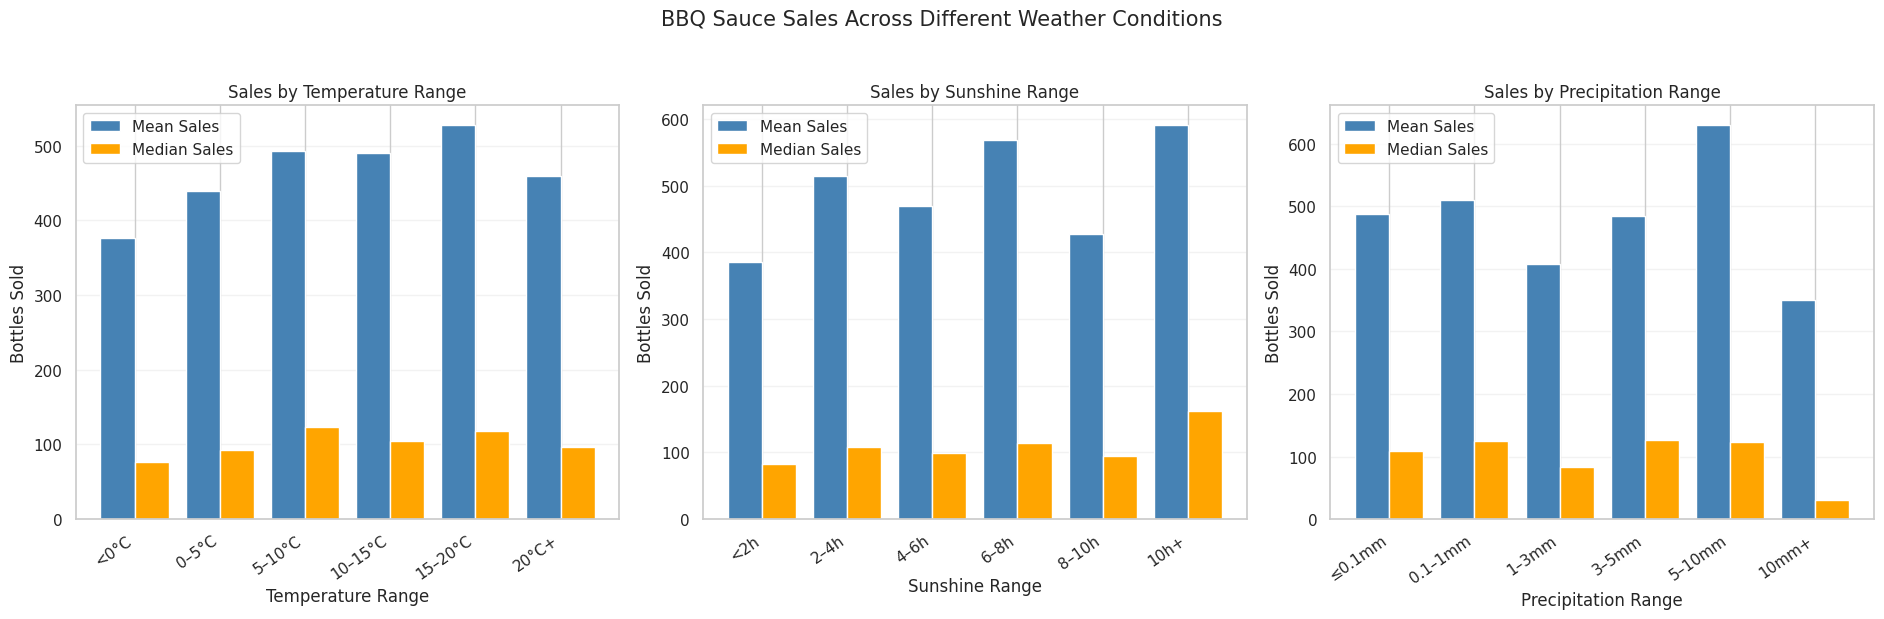

In [ ]:

# Cell 16: Weather Range Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

weather_bins = {
    "mean_temp_nationwide": {
        "bins": [-np.inf, 0, 5, 10, 15, 20, np.inf],
        "labels": ["<0°C", "0–5°C", "5–10°C", "10–15°C",
                   "15–20°C", "20°C+"],
        "title": "Temperature"
    },
    "mean_sun_hours_nationwide": {
        "bins": [-np.inf, 2, 4, 6, 8, 10, np.inf],
        "labels": ["<2h", "2–4h", "4–6h", "6–8h",
                   "8–10h", "10h+"],
        "title": "Sunshine"
    },
    "mean_precipitation_mm_nationwide": {
        "bins": [-np.inf, 0.1, 1, 3, 5, 10, np.inf],
        "labels": ["≤0.1mm", "0.1–1mm", "1–3mm",
                   "3–5mm", "5–10mm", "10mm+"],
        "title": "Precipitation"
    }
}

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (feature, config) in zip(axes, weather_bins.items()):

    temp = df[[feature, "amount"]].dropna().copy()

    temp["weather_range"] = pd.cut(
        temp[feature],
        bins=config["bins"],
        labels=config["labels"],
        include_lowest=True
    )

    summary = (
        temp.groupby("weather_range", observed=False)["amount"]
        .agg(["mean", "median", "count"])
        .reset_index()
    )

    print(f"\n{config['title']} — Sales Summary")
    display(summary.round(2))

    x = np.arange(len(summary))

    ax.bar(
        x - 0.2,
        summary["mean"],
        width=0.4,
        label="Mean Sales",
        color="steelblue"
    )

    ax.bar(
        x + 0.2,
        summary["median"],
        width=0.4,
        label="Median Sales",
        color="orange"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        summary["weather_range"],
        rotation=35,
        ha="right"
    )

    ax.set_title(f"Sales by {config['title']} Range")
    ax.set_xlabel(config["title"] + " Range")
    ax.set_ylabel("Bottles Sold")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

plt.suptitle(
    "BBQ Sauce Sales Across Different Weather Conditions",
    fontsize=15,
    y=1.03
)

plt.tight_layout()
plt.show()


The weather range analysis indicates that BBQ sauce sales vary across different meteorological conditions, although no strong or consistently monotonic relationships are observed. Moderate temperatures are associated with somewhat higher sales, while days exceeding ten sunshine hours exhibit the highest median sales (162 bottles). Precipitation displays an inconsistent relationship, although days with rainfall exceeding 10 mm show comparatively low median sales. Large differences between mean and median values suggest that extreme sales observations influence the averages. Overall, the findings indicate that weather may contribute to demand variation, but its independent effect remains uncertain due to potential seasonal confounding.

In [ ]:


# Cell 17A: Validate sales and climate date coverage

sales_17 = sales_df.copy()
climate_17 = pd.read_csv(climate_matches[0])

sales_17["date"] = pd.to_datetime(
    sales_17["date"]
).dt.normalize()

climate_17["date"] = pd.to_datetime(
    climate_17["date"]
).dt.normalize()

weather_features = [
    "mean_temp_nationwide",
    "mean_sun_hours_nationwide",
    "mean_precipitation_mm_nationwide"
]



In [ ]:


# Cell 17B: Verify original climate CSV coverage

print("Original climate records:", len(climate_17))
print("Unique dates:", climate_17["date"].nunique())

start = climate_17["date"].min()
end = climate_17["date"].max()

expected_days = (end - start).days + 1

print("Date range:", start, "to", end)
print("Expected calendar days:", expected_days)
print(
    "Missing calendar dates:",
    expected_days - climate_17["date"].nunique()
)

print("\nMissing weather values:")
display(climate_17[weather_features].isna().sum())

# Compare original climate dates against sales dates
climate_dates = set(climate_17["date"])
sales_dates = set(sales_17["date"])

print(
    "\nClimate dates not in sales:",
    len(climate_dates - sales_dates)
)

print(
    "Sales dates not in climate:",
    len(sales_dates - climate_dates)
)


Original climate records: 1386
Unique dates: 1385
Date range: 2021-01-03 00:00:00 to 2026-07-29 00:00:00
Expected calendar days: 2034
Missing calendar dates: 649

Missing weather values:


,0
mean_temp_nationwide,0
mean_sun_hours_nationwide,0
mean_precipitation_mm_nationwide,0



Climate dates not in sales: 0
Sales dates not in climate: 0


In [ ]:

# CELL 17C: CREATE CALENDAR-BASED WEATHER LAGS

# Resolve duplicate climate dates by averaging values
# This is a provisional aggregation for duplicate measurements.
weather_daily = (
    climate_17
    .groupby("date")[weather_features]
    .mean()
    .sort_index()
)

# Create continuous calendar index
weather_daily = weather_daily.asfreq("D")

# Missing dates remain NaN
print("Weather calendar days:", len(weather_daily))
print(
    "Dates with no weather observations:",
    weather_daily[weather_features].isna().all(axis=1).sum()
)

# Generate lagged weather features
for feature in weather_features:
    for lag in range(8):
        weather_daily[f"{feature}_lag{lag}"] = (
            weather_daily[feature].shift(lag)
        )

# Join weather features to original sales dates
sales_lagged = sales_17[["date", "amount"]].merge(
    weather_daily[
        [f"{feature}_lag{lag}"
         for feature in weather_features
         for lag in range(8)]
    ],
    left_on="date",
    right_index=True,
    how="left",
    validate="one_to_one"
)

print("\nPrepared dataset shape:", sales_lagged.shape)
print("Sales observations retained:", len(sales_lagged))

print("\nAvailable observations by lag:")
availability = []

for lag in range(8):
    feature = f"mean_temp_nationwide_lag{lag}"

    availability.append({
        "Lag (Days)": lag,
        "Available Observations":
            sales_lagged[feature].notna().sum()
    })

display(pd.DataFrame(availability))


Weather calendar days: 2034
Dates with no weather observations: 649

Prepared dataset shape: (1385, 26)
Sales observations retained: 1385

Available observations by lag:


,Lag (Days),Available Observations
0,0,1385
1,1,1071
2,2,808
3,3,803
4,4,800
5,5,806
6,6,1062
7,7,1298


LAGGED WEATHER CORRELATION RESULTS


,Weather Variable,Lag (Days),Pearson,Spearman,Observations
0,mean_temp_nationwide,0,0.034,0.041,1385
1,mean_temp_nationwide,1,-0.000,0.007,1071
2,mean_temp_nationwide,2,-0.032,-0.025,808
3,mean_temp_nationwide,3,0.027,0.003,803
4,mean_temp_nationwide,4,0.070,0.067,800
5,mean_temp_nationwide,5,0.064,0.075,806
6,mean_temp_nationwide,6,0.038,0.034,1062
7,mean_temp_nationwide,7,0.027,0.018,1298
8,mean_sun_hours_nationwide,0,0.065,0.116,1385
9,mean_sun_hours_nationwide,1,0.085,0.089,1071


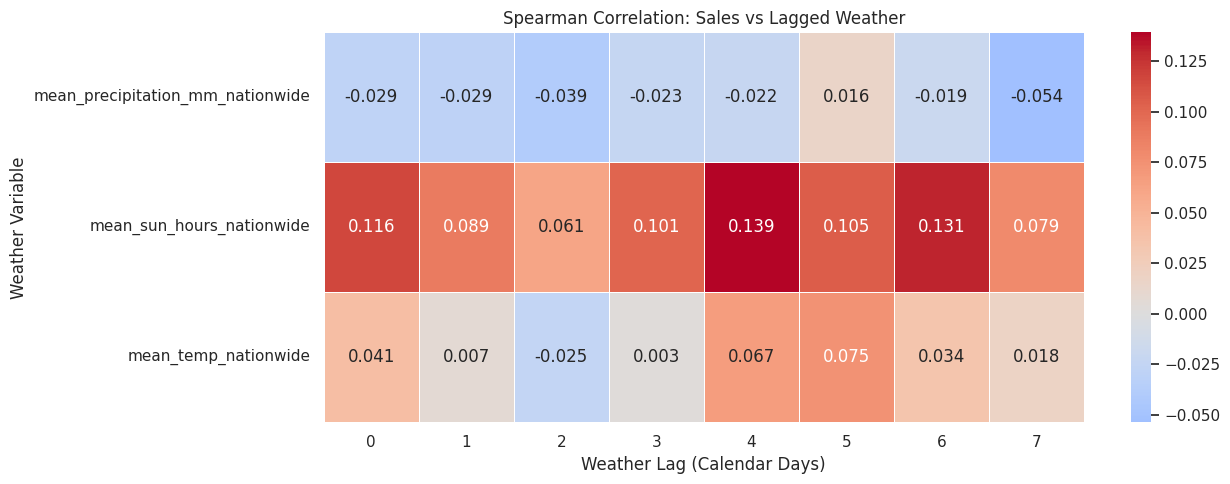


STRONGEST OBSERVED CORRELATION PER VARIABLE


,Weather Variable,Lag (Days),Spearman,Observations
23,mean_precipitation_mm_nationwide,7,-0.054,1298
12,mean_sun_hours_nationwide,4,0.139,800
5,mean_temp_nationwide,5,0.075,806


In [ ]:

# CELL 17D: LAGGED WEATHER CORRELATION ANALYSIS

results = []

for feature in weather_features:

    for lag in range(8):

        lag_column = f"{feature}_lag{lag}"

        comparison = sales_lagged[
            ["amount", lag_column]
        ].dropna()

        results.append({
            "Weather Variable": feature,
            "Lag (Days)": lag,
            "Pearson": comparison["amount"].corr(
                comparison[lag_column],
                method="pearson"
            ),
            "Spearman": comparison["amount"].corr(
                comparison[lag_column],
                method="spearman"
            ),
            "Observations": len(comparison)
        })

lag_results = pd.DataFrame(results)

print("LAGGED WEATHER CORRELATION RESULTS")
display(lag_results.round(3))

# Spearman heatmap
spearman_pivot = lag_results.pivot(
    index="Weather Variable",
    columns="Lag (Days)",
    values="Spearman"
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    spearman_pivot,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation: Sales vs Lagged Weather")
plt.xlabel("Weather Lag (Calendar Days)")
plt.ylabel("Weather Variable")
plt.tight_layout()
plt.show()

# Identify strongest absolute Spearman correlation
strongest = (
    lag_results
    .assign(abs_spearman=lag_results["Spearman"].abs())
    .sort_values("abs_spearman", ascending=False)
    .groupby("Weather Variable")
    .head(1)
    .sort_values("Weather Variable")
)

print("\nSTRONGEST OBSERVED CORRELATION PER VARIABLE")
display(
    strongest[
        ["Weather Variable", "Lag (Days)",
         "Spearman", "Observations"]
    ].round(3)
)


The lagged-weather analysis identified weak associations between BBQ sauce sales and preceding weather conditions, with sunshine exhibiting the strongest positive Spearman correlation (0.139 at a four-day lag). However, both the sales and climate datasets contain observations for the same 1,385 dates, leaving 649 calendar dates unrecorded. Consequently, the number of observations available for lagged comparisons varies substantially. The findings therefore provide limited evidence of delayed weather relationships and should be interpreted cautiously.

,Lag (Days),Autocorrelation,Observations
0,1,0.044,1071
1,2,0.037,808
2,3,-0.004,803
3,4,0.027,800
4,5,0.074,806
5,6,0.015,1062
6,7,0.069,1298
7,8,0.048,1053
8,9,0.022,800
9,10,-0.025,788


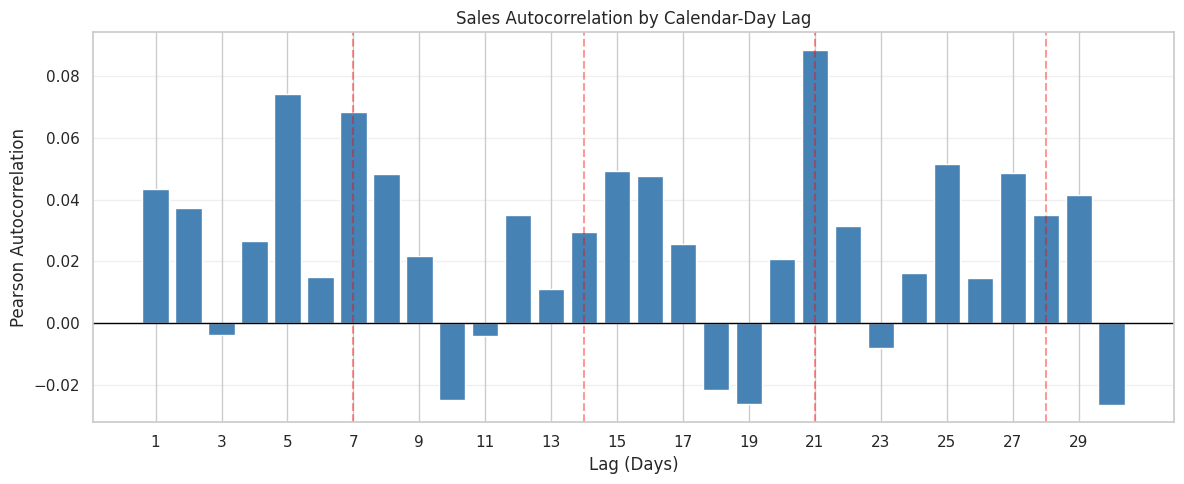


Strongest autocorrelations:


,Lag (Days),Autocorrelation,Observations,abs_corr
20,21,0.089,1272,0.089
4,5,0.074,806,0.074
6,7,0.069,1298,0.069
24,25,0.051,782,0.051
14,15,0.049,1046,0.049
26,27,0.049,1045,0.049
7,8,0.048,1053,0.048
15,16,0.048,800,0.048
0,1,0.044,1071,0.044
28,29,0.041,1033,0.041


In [ ]:

# CELL 18: SALES AUTOCORRELATION

sales_series = (
    sales_df.copy()
    .assign(date=lambda x: pd.to_datetime(x["date"]))
    .set_index("date")["amount"]
    .sort_index()
    .asfreq("D")
)

lags = range(1, 31)

autocorr_results = pd.DataFrame({
    "Lag (Days)": list(lags),
    "Autocorrelation": [
        sales_series.autocorr(lag=lag)
        for lag in lags
    ],
    "Observations": [
        (sales_series.notna() &
         sales_series.shift(lag).notna()).sum()
        for lag in lags
    ]
})

display(autocorr_results.round(3))

plt.figure(figsize=(12, 5))

plt.bar(
    autocorr_results["Lag (Days)"],
    autocorr_results["Autocorrelation"],
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)

for lag in [7, 14, 21, 28]:
    plt.axvline(
        lag,
        color="red",
        linestyle="--",
        alpha=0.4
    )

plt.title("Sales Autocorrelation by Calendar-Day Lag")
plt.xlabel("Lag (Days)")
plt.ylabel("Pearson Autocorrelation")
plt.xticks(range(1, 31, 2))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStrongest autocorrelations:")
display(
    autocorr_results
    .assign(abs_corr=lambda x: x["Autocorrelation"].abs())
    .sort_values("abs_corr", ascending=False)
    .head(10)
    .round(3)
)


Sales autocorrelation analysis across 30 calendar-day lags reveals consistently weak temporal dependence, with the highest correlation occurring at a 21-day lag (approximately 0.088). Weekly intervals exhibit only small positive correlations, suggesting limited evidence of strong recurring weekly sales patterns. These findings indicate that historical sales alone may have limited predictive power, although lagged sales features may still contribute when combined with seasonal and weather-related variables.

In [ ]:

# CELL 19: FINAL EDA SUMMARY

sales = sales_df.copy()
sales["date"] = pd.to_datetime(sales["date"])

total_days = (
    sales["date"].max() - sales["date"].min()
).days + 1

monthly_median = (
    sales.groupby(sales["date"].dt.month)["amount"]
    .median()
)

summary = pd.DataFrame({
    "Metric": [
        "Total recorded sales days",
        "Missing calendar days",
        "Mean daily sales",
        "Median daily sales",
        "Sales standard deviation",
        "Sales skewness",
        "Maximum daily sales",
        "Zero-sales observations",
        "Month with highest median sales",
        "Month with lowest median sales"
    ],
    "Value": [
        len(sales),
        total_days - sales["date"].nunique(),
        round(sales["amount"].mean(), 2),
        round(sales["amount"].median(), 2),
        round(sales["amount"].std(), 2),
        round(sales["amount"].skew(), 2),
        sales["amount"].max(),
        (sales["amount"] == 0).sum(),
        monthly_median.idxmax(),
        monthly_median.idxmin()
    ]
})

display(summary)


,Metric,Value
0,Total recorded sales days,1385.00
1,Missing calendar days,649.00
2,Mean daily sales,483.72
3,Median daily sales,105.00
4,Sales standard deviation,860.14
5,Sales skewness,2.79
6,Maximum daily sales,5703.00
7,Zero-sales observations,115.00
8,Month with highest median sales,4.00
9,Month with lowest median sales,11.00


The exploratory analysis identified 1,385 recorded sales days and 649 missing calendar dates between January 2021 and July 2026. Daily sales exhibit substantial variability and a strongly right-skewed distribution, with a mean of 483.72 bottles compared with a median of 105 bottles. Seasonal analysis indicates stronger sales during spring, particularly April, while November records the lowest monthly median. Weather variables exhibit weak same-day and lagged correlations with sales, and historical sales autocorrelations are also low. These findings suggest that forecasting may be challenging and that calendar, weather, and historical sales features should be evaluated comparatively.